# Direct Spherical Context Encoder–Decoder

教授方案：

\[
x_{\text{context}}\rightarrow z_{\text{spherical}}\rightarrow\hat y_{\text{center word}}
\]

不使用预训练 Word2Vec。输入是上下文，输出是中心词，因此这是 **encoder–decoder with a spherical bottleneck**，不是传统 autoencoder。

`nn.EmbeddingBag` 等价于对 context multi-hot vector 做线性变换 \(Wx_{\text{context}}\)，但无需显式构造30,000维稠密向量。该矩阵从零开始训练，并不是外部 Word2Vec。


In [1]:
import random, urllib.request, zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display


In [2]:
SEED = 42
VOCAB_SIZE = 30_000
WINDOW_RADIUS = 5
MIN_COUNT = 5
BATCH_SIZE = 256
EPOCHS = 50
LEARNING_RATE = 2e-3
CONTEXT_HIDDEN_DIM = 256
ENCODER_HIDDEN_DIM = 128
LATENT_DIM = 32
SAMPLE_ALPHA = 0.15
BETA_RIESZ = 1e-3
RIESZ_SUBSAMPLE = 256
MAX_TOKENS = 3_000_000

DATA_DIR = Path("./data")
TEXT8_PATH = DATA_DIR / "text8"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)


Device: cuda


## 1. Load text8


In [3]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not TEXT8_PATH.exists():
    zip_path = DATA_DIR / "text8.zip"
    urllib.request.urlretrieve(
        "http://mattmahoney.net/dc/text8.zip",
        zip_path,
    )
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATA_DIR)

tokens = TEXT8_PATH.read_text(
    encoding="utf-8"
).split()

if MAX_TOKENS is not None:
    tokens = tokens[:MAX_TOKENS]

print("Tokens:", len(tokens))


Tokens: 3000000


## 2. Vocabulary


In [4]:
counter = Counter(tokens)

words = [
    word
    for word, count in counter.most_common(VOCAB_SIZE - 2)
    if count >= MIN_COUNT
]

idx_to_word = ["<pad>", "<unk>"] + words
word_to_idx = {
    word: index
    for index, word in enumerate(idx_to_word)
}

PAD_ID = word_to_idx["<pad>"]
UNK_ID = word_to_idx["<unk>"]

encoded_tokens = np.asarray(
    [word_to_idx.get(word, UNK_ID) for word in tokens],
    dtype=np.int64,
)

ACTUAL_VOCAB_SIZE = len(idx_to_word)

print("Vocabulary size:", ACTUAL_VOCAB_SIZE)
print("UNK ratio:", float(np.mean(encoded_tokens == UNK_ID)))


Vocabulary size: 27323
UNK ratio: 0.036664


## 3. Context → center word dataset

窗口半径为5：

```text
5 left words + center word + 5 right words
```

模型输入10个上下文词，输出中心词。


In [5]:
class ContextCenterDataset(Dataset):
    def __init__(self, token_ids, window_radius=5):
        self.token_ids = token_ids
        self.window_radius = int(window_radius)

    def __len__(self):
        return len(self.token_ids) - 2 * self.window_radius

    def __getitem__(self, index):
        center_position = index + self.window_radius

        left = self.token_ids[
            center_position - self.window_radius:
            center_position
        ]

        right = self.token_ids[
            center_position + 1:
            center_position + self.window_radius + 1
        ]

        context = np.concatenate([left, right])
        center = self.token_ids[center_position]

        return (
            torch.tensor(context, dtype=torch.long),
            torch.tensor(center, dtype=torch.long),
        )


split = int(0.90 * len(encoded_tokens))

train_dataset = ContextCenterDataset(
    encoded_tokens[:split],
    WINDOW_RADIUS,
)

valid_dataset = ContextCenterDataset(
    encoded_tokens[split - 2 * WINDOW_RADIUS:],
    WINDOW_RADIUS,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Train:", len(train_dataset))
print("Validation:", len(valid_dataset))


Train: 2699990
Validation: 300000


## 4. Direct spherical model


In [6]:
def riesz_energy(points, subsample=256, s=1.0):
    if points.size(0) < 2:
        return torch.zeros(
            (),
            device=points.device,
            dtype=points.dtype,
        )

    if subsample is not None and points.size(0) > subsample:
        indices = torch.randperm(
            points.size(0),
            device=points.device,
        )[:subsample]
        points = points[indices]

    distances = torch.cdist(points, points)

    mask = torch.triu(
        torch.ones_like(distances, dtype=torch.bool),
        diagonal=1,
    )

    valid = distances[mask]

    return torch.mean(
        1.0 / torch.clamp(valid, min=1e-4).pow(s)
    )


class DirectSphericalContextModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        context_hidden_dim=256,
        encoder_hidden_dim=128,
        latent_dim=32,
        sample_alpha=0.15,
    ):
        super().__init__()

        self.sample_alpha = float(sample_alpha)

        self.context_projection = nn.EmbeddingBag(
            vocab_size,
            context_hidden_dim,
            mode="sum",
        )

        self.encoder = nn.Sequential(
            nn.Linear(context_hidden_dim, encoder_hidden_dim),
            nn.ReLU(),
            nn.Linear(encoder_hidden_dim, latent_dim),
        )

        self.decoder = nn.Linear(
            latent_dim,
            vocab_size,
        )

    def encode_context(self, context_ids):
        batch_size, context_length = context_ids.shape

        flattened = context_ids.reshape(-1)

        offsets = torch.arange(
            0,
            batch_size * context_length,
            context_length,
            device=context_ids.device,
        )

        context_hidden = self.context_projection(
            flattened,
            offsets,
        )

        raw_direction = self.encoder(context_hidden)

        return F.normalize(
            raw_direction,
            p=2,
            dim=-1,
            eps=1e-8,
        )

    def sample_on_sphere(self, mean_direction):
        ambient_noise = torch.randn_like(mean_direction)

        tangent_noise = (
            ambient_noise
            - (
                ambient_noise * mean_direction
            ).sum(dim=-1, keepdim=True)
            * mean_direction
        )

        tangent_noise = F.normalize(
            tangent_noise,
            p=2,
            dim=-1,
            eps=1e-8,
        )

        theta = self.sample_alpha * torch.rand(
            mean_direction.size(0),
            1,
            device=mean_direction.device,
        )

        z = (
            mean_direction * torch.cos(theta)
            + tangent_noise * torch.sin(theta)
        )

        return F.normalize(
            z,
            p=2,
            dim=-1,
            eps=1e-8,
        )

    def forward(self, context_ids, sample=True):
        mean_direction = self.encode_context(context_ids)

        z = (
            self.sample_on_sphere(mean_direction)
            if sample
            else mean_direction
        )

        logits = self.decoder(z)

        return {
            "logits": logits,
            "mean_direction": mean_direction,
            "z": z,
        }


model = DirectSphericalContextModel(
    vocab_size=ACTUAL_VOCAB_SIZE,
    context_hidden_dim=CONTEXT_HIDDEN_DIM,
    encoder_hidden_dim=ENCODER_HIDDEN_DIM,
    latent_dim=LATENT_DIM,
    sample_alpha=SAMPLE_ALPHA,
).to(DEVICE)

print(model)


DirectSphericalContextModel(
  (context_projection): EmbeddingBag(27323, 256, mode='sum')
  (encoder): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Linear(in_features=32, out_features=27323, bias=True)
)


## 5. Loss

\[
\mathcal L =
\mathcal L_{\text{center-word classification}}
+
\beta\mathcal L_{\text{Riesz}}
\]


In [7]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []

for epoch in range(EPOCHS):
    model.train()

    totals = defaultdict(float)
    steps = 0

    for context_ids, center_ids in train_loader:
        context_ids = context_ids.to(
            DEVICE,
            non_blocking=True,
        )

        center_ids = center_ids.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(set_to_none=True)

        output = model(
            context_ids,
            sample=True,
        )

        center_loss = F.cross_entropy(
            output["logits"],
            center_ids,
        )

        riesz_loss = riesz_energy(
            output["mean_direction"],
            subsample=RIESZ_SUBSAMPLE,
        )

        loss = (
            center_loss
            + BETA_RIESZ * riesz_loss
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0,
        )

        optimizer.step()

        top1 = (
            output["logits"]
            .argmax(dim=-1)
            .eq(center_ids)
            .float()
            .mean()
        )

        totals["loss"] += float(loss.detach().cpu())
        totals["center"] += float(center_loss.detach().cpu())
        totals["riesz"] += float(riesz_loss.detach().cpu())
        totals["top1"] += float(top1.detach().cpu())
        steps += 1

    row = {
        "epoch": epoch + 1,
        "loss": totals["loss"] / steps,
        "center_loss": totals["center"] / steps,
        "riesz": totals["riesz"] / steps,
        "train_top1": totals["top1"] / steps,
    }

    history.append(row)
    print(row)

history = pd.DataFrame(history)
display(history)


{'epoch': 1, 'loss': 6.68824777994674, 'center_loss': 6.6868586338582485, 'riesz': 1.3891459440375726, 'train_top1': 0.10827855055093358}
{'epoch': 2, 'loss': 6.267482053954375, 'center_loss': 6.266685772385204, 'riesz': 0.7962831495677825, 'train_top1': 0.13200728974390835}
{'epoch': 3, 'loss': 6.068026468834516, 'center_loss': 6.067266074381609, 'riesz': 0.760393303492018, 'train_top1': 0.14354395121265343}
{'epoch': 4, 'loss': 5.922989739075966, 'center_loss': 5.922245093767277, 'riesz': 0.7446442670230787, 'train_top1': 0.1518020014876131}
{'epoch': 5, 'loss': 5.805171401825993, 'center_loss': 5.80443529627431, 'riesz': 0.7361040534798631, 'train_top1': 0.1590259172551449}
{'epoch': 6, 'loss': 5.7052321872564695, 'center_loss': 5.704501178125143, 'riesz': 0.7310094119440699, 'train_top1': 0.16563974679607096}
{'epoch': 7, 'loss': 5.617873308974397, 'center_loss': 5.617144951404887, 'riesz': 0.7283574561377866, 'train_top1': 0.17189013654500532}
{'epoch': 8, 'loss': 5.54050996471516

,epoch,loss,center_loss,riesz,train_top1
0,1,6.688248,6.686859,1.389146,0.108279
1,2,6.267482,6.266686,0.796283,0.132007
2,3,6.068026,6.067266,0.760393,0.143544
3,4,5.922990,5.922245,0.744644,0.151802
4,5,5.805171,5.804435,0.736104,0.159026
5,6,5.705232,5.704501,0.731009,0.165640
6,7,5.617873,5.617145,0.728357,0.171890
7,8,5.540510,5.539783,0.726748,0.177676
8,9,5.470666,5.469940,0.726139,0.182933
9,10,5.407044,5.406318,0.726028,0.188147


## 6. Validation


In [8]:
def evaluate_model(model, loader):
    model.eval()

    totals = defaultdict(float)
    steps = 0

    with torch.no_grad():
        for context_ids, center_ids in loader:
            context_ids = context_ids.to(DEVICE)
            center_ids = center_ids.to(DEVICE)

            output = model(
                context_ids,
                sample=False,
            )

            loss = F.cross_entropy(
                output["logits"],
                center_ids,
            )

            top5 = torch.topk(
                output["logits"],
                k=5,
                dim=-1,
            ).indices

            totals["loss"] += float(loss.cpu())

            totals["top1"] += float(
                top5[:, 0]
                .eq(center_ids)
                .float()
                .mean()
                .cpu()
            )

            totals["top5"] += float(
                top5
                .eq(center_ids.unsqueeze(1))
                .any(dim=1)
                .float()
                .mean()
                .cpu()
            )

            totals["latent_norm"] += float(
                output["z"]
                .norm(dim=-1)
                .mean()
                .cpu()
            )

            steps += 1

    return {
        key: value / steps
        for key, value in totals.items()
    }


display(
    pd.DataFrame([
        evaluate_model(model, valid_loader)
    ])
)


,loss,top1,top5,latent_norm
0,7.486697,0.091826,0.209036,1.0


## 7. Inspect predictions


In [9]:
model.eval()

context_batch, center_batch = next(
    iter(valid_loader)
)

context_batch = context_batch[:12].to(DEVICE)
center_batch = center_batch[:12].to(DEVICE)

with torch.no_grad():
    output = model(
        context_batch,
        sample=False,
    )

    top5_ids = torch.topk(
        output["logits"],
        k=5,
        dim=-1,
    ).indices.cpu().numpy()

rows = []

for index in range(len(context_batch)):
    rows.append({
        "context": " ".join(
            idx_to_word[token_id]
            for token_id in context_batch[index].cpu().numpy()
        ),
        "target": idx_to_word[
            int(center_batch[index].cpu())
        ],
        "top5_predictions": [
            idx_to_word[token_id]
            for token_id in top5_ids[index]
        ],
    })

display(pd.DataFrame(rows))


,context,target,top5_predictions
0,the well informed is <unk> as an inspiration o...,offered,"[as, <unk>, art, writer, character]"
1,well informed is <unk> offered an inspiration ...,as,"[as, that, also, which, best]"
2,informed is <unk> offered as inspiration of th...,an,"[also, to, as, many, for]"
3,is <unk> offered as an of the baroque which ap...,inspiration,"[<unk>, variety, style, art, character]"
4,<unk> offered as an inspiration the baroque wh...,of,"[<unk>, new, was, him, greek]"
5,offered as an inspiration of baroque which app...,the,"[<unk>, the, variety, piece, was]"
6,as an inspiration of the which appeared howeve...,baroque,"[new, between, <unk>, was, story]"
7,an inspiration of the baroque appeared however...,which,"[new, period, style, <unk>, as]"
8,inspiration of the baroque which however a gen...,appeared,"[was, became, period, made, continued]"
9,of the baroque which appeared a generation lat...,however,"[in, on, with, at, was]"


## 8. Build word-level spherical representations

这里有一个重要区别：模型原始 latent 表示的是一个**上下文窗口**，不是单独的词。

为了得到每个词的球面表示，我们聚合“该词作为中心词时”的所有 context latent：

\[
e_w =
\operatorname{normalize}
\left(
\sum_{i:y_i=w}z_i
\right)
\]


In [10]:
def build_word_spherical_embeddings(
    model,
    loader,
    vocab_size,
    max_batches=None,
):
    model.eval()

    sums = np.zeros(
        (vocab_size, LATENT_DIM),
        dtype=np.float64,
    )

    counts = np.zeros(
        vocab_size,
        dtype=np.int64,
    )

    with torch.no_grad():
        for batch_index, (
            context_ids,
            center_ids,
        ) in enumerate(loader):
            if (
                max_batches is not None
                and batch_index >= max_batches
            ):
                break

            output = model(
                context_ids.to(DEVICE),
                sample=False,
            )

            latents = output["z"].cpu().numpy()
            centers = center_ids.numpy()

            for word_id in np.unique(centers):
                mask = centers == word_id
                sums[word_id] += latents[mask].sum(axis=0)
                counts[word_id] += int(mask.sum())

    embeddings = np.zeros_like(sums)
    valid = counts > 0

    norms = np.linalg.norm(
        sums[valid],
        axis=1,
        keepdims=True,
    )

    embeddings[valid] = (
        sums[valid]
        / np.clip(norms, 1e-12, None)
    )

    return embeddings, counts


word_spherical_embeddings, word_context_counts = (
    build_word_spherical_embeddings(
        model,
        train_loader,
        ACTUAL_VOCAB_SIZE,
    )
)

print(
    "Words represented:",
    int(np.sum(word_context_counts > 0)),
)


Words represented: 27181


## 9. Nearest neighbors


In [11]:
def nearest_words(query_word, top_k=10):
    if query_word not in word_to_idx:
        raise KeyError(query_word)

    query_id = word_to_idx[query_word]
    query = word_spherical_embeddings[query_id]

    if np.linalg.norm(query) < 1e-12:
        raise ValueError("No representation for this word.")

    similarities = (
        word_spherical_embeddings @ query
    )

    similarities[word_context_counts == 0] = -np.inf
    similarities[query_id] = -np.inf

    nearest_ids = np.argsort(
        -similarities
    )[:top_k]

    return pd.DataFrame({
        "word": [
            idx_to_word[index]
            for index in nearest_ids
        ],
        "cosine_similarity": similarities[nearest_ids],
        "context_count": word_context_counts[nearest_ids],
    })


for query_word in [
    "king",
    "queen",
    "france",
    "italy",
    "man",
    "woman",
]:
    if query_word in word_to_idx:
        print("Query:", query_word)
        display(
            nearest_words(
                query_word,
                top_k=10,
            )
        )


Query: king


,word,cosine_similarity,context_count
0,prince,0.893793,245
1,regent,0.888737,29
2,emperor,0.879003,535
3,grandson,0.878657,41
4,macedon,0.856865,53
5,queen,0.844880,286
6,son,0.844073,775
7,ruler,0.841181,114
8,empress,0.836727,24
9,sancho,0.829213,16


Query: queen


,word,cosine_similarity,context_count
0,lord,0.853423,344
1,king,0.844880,1304
2,consort,0.824991,14
3,prince,0.814062,245
4,bishop,0.797012,191
5,princess,0.793187,99
6,theresa,0.791983,7
7,bentinck,0.786843,5
8,lady,0.776479,68
9,toulouse,0.773817,28


Query: france


...

,word,cosine_similarity,context_count
0,france,0.903965,637
1,spain,0.897890,294
2,switzerland,0.882866,96
3,germany,0.882749,706
4,india,0.867642,447
5,prussia,0.863410,71
6,persia,0.862374,88
7,russia,0.856913,388
8,hungary,0.856630,154
9,thrace,0.856575,32


Query: man


,word,cosine_similarity,context_count
0,woman,0.916690,264
1,evil,0.860726,153
2,passion,0.857415,67
3,hero,0.850737,120
4,dream,0.849514,69
5,love,0.835266,363
6,forehead,0.832811,10
7,child,0.819378,226
8,sacrifice,0.812128,81
9,carefree,0.809947,6


Query: woman


,word,cosine_similarity,context_count
0,man,0.916690,959
1,child,0.876790,226
2,herself,0.816417,93
3,dione,0.800072,5
4,sacrifice,0.796507,81
5,girl,0.793964,109
6,curse,0.788774,27
7,hero,0.784618,120
8,villain,0.782311,13
9,wise,0.781710,47


## 10. Save model and embeddings


In [12]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "word_to_idx": word_to_idx,
        "idx_to_word": idx_to_word,
    },
    "direct_spherical_context_model.pt",
)

np.savez_compressed(
    "direct_spherical_word_embeddings.npz",
    embeddings=word_spherical_embeddings,
    counts=word_context_counts,
    words=np.asarray(
        idx_to_word,
        dtype=object,
    ),
)

print("Saved.")


Saved.


## 11. Semantic relation transfer on the sphere

这一部分加入之前使用过的 **relation extraction + parallel transport + Exp-map** 测试。

给定关系：

\[
a\rightarrow b
\]

先提取球面 relation tangent vector：

\[
v_{ab}=\log_a(b)
\]

然后把 relation 搬到新的起点 \(c\)：

\[
\tilde v_{ab}^{(c)} = PT_{a\rightarrow c}(v_{ab})
\]

最后：

\[
\hat d=\operatorname{Exp}_c(\tilde v_{ab}^{(c)})
\]

如果语义 relation 在 spherical latent space 中可以迁移，那么 \(\hat d\) 应该靠近预期 target \(d\)。

我们同时记录 relation angle、transport 前后 norm、target rank、Top-1/Top-5、endpoint 到 target 的角度距离以及 transported direction 和真实关系方向之间的夹角。


In [13]:
EPS_GEOM = 1e-8

def normalize_np(v):
    v = np.asarray(v, dtype=np.float64)
    norm = np.linalg.norm(v)
    if norm < EPS_GEOM:
        raise ValueError("Near-zero vector.")
    return v / norm

def spherical_distance_np(x, y):
    x = normalize_np(x)
    y = normalize_np(y)
    return float(np.arccos(np.clip(np.dot(x, y), -1.0, 1.0)))

def log_map_sphere(x, y):
    x = normalize_np(x)
    y = normalize_np(y)

    cosine = np.clip(np.dot(x, y), -1.0, 1.0)
    theta = np.arccos(cosine)

    if theta < EPS_GEOM:
        return np.zeros_like(x)

    direction = y - cosine * x
    direction_norm = np.linalg.norm(direction)

    if direction_norm < EPS_GEOM:
        return np.zeros_like(x)

    return theta * direction / direction_norm

def exp_map_sphere(x, tangent):
    x = normalize_np(x)
    tangent = np.asarray(tangent, dtype=np.float64)

    tangent = tangent - np.dot(tangent, x) * x
    tangent_norm = np.linalg.norm(tangent)

    if tangent_norm < EPS_GEOM:
        return x.copy()

    endpoint = (
        np.cos(tangent_norm) * x
        + np.sin(tangent_norm) * tangent / tangent_norm
    )

    return normalize_np(endpoint)

def parallel_transport_sphere(tangent, x, y):
    x = normalize_np(x)
    y = normalize_np(y)

    tangent = np.asarray(tangent, dtype=np.float64)
    tangent = tangent - np.dot(tangent, x) * x

    denominator = 1.0 + np.dot(x, y)

    if abs(denominator) < EPS_GEOM:
        raise ValueError(
            "Parallel transport is unstable for near-antipodal points."
        )

    transported = (
        tangent
        - (np.dot(tangent, y) / denominator) * (x + y)
    )

    transported = transported - np.dot(transported, y) * y
    return transported

def angle_between_vectors_deg(v1, v2):
    n1 = np.linalg.norm(v1)
    n2 = np.linalg.norm(v2)

    if n1 < EPS_GEOM or n2 < EPS_GEOM:
        return np.nan

    cosine = np.clip(
        np.dot(v1, v2) / (n1 * n2),
        -1.0,
        1.0,
    )

    return float(np.degrees(np.arccos(cosine)))


## 12.  Direct Spherical Context Model  word representations




In [14]:
def get_word_latent(word):
    if word not in word_to_idx:
        raise KeyError(f"'{word}' is not in the vocabulary.")

    word_id = word_to_idx[word]

    if word_context_counts[word_id] <= 0:
        raise ValueError(f"'{word}' has no spherical representation.")

    return normalize_np(word_spherical_embeddings[word_id])

def nearest_words_to_vector(vector, top_k=10, exclude_words=None):
    vector = normalize_np(vector)

    similarities = word_spherical_embeddings @ vector
    similarities[word_context_counts == 0] = -np.inf

    if exclude_words is not None:
        for word in exclude_words:
            if word in word_to_idx:
                similarities[word_to_idx[word]] = -np.inf

    nearest_ids = np.argsort(-similarities)[:top_k]

    return pd.DataFrame({
        "rank": np.arange(1, len(nearest_ids) + 1),
        "word": [idx_to_word[i] for i in nearest_ids],
        "cosine_similarity": similarities[nearest_ids],
        "angle_deg": [
            float(np.degrees(np.arccos(np.clip(similarities[i], -1.0, 1.0))))
            for i in nearest_ids
        ],
    })

def rank_of_target(query_vector, target_word, exclude_words=None):
    query_vector = normalize_np(query_vector)
    similarities = word_spherical_embeddings @ query_vector

    similarities[word_context_counts == 0] = -np.inf

    if exclude_words is not None:
        for word in exclude_words:
            if word in word_to_idx and word != target_word:
                similarities[word_to_idx[word]] = -np.inf

    target_id = word_to_idx[target_word]
    target_similarity = similarities[target_id]

    rank = int(1 + np.sum(similarities > target_similarity))

    return rank, float(target_similarity)


## 13. Single relation transfer

对于四元组 \((a,b,c,d)\)，例如：

\[
(\text{man},\text{woman},\text{king},\text{queen})
\]

执行：

\[
v_{ab}=\log_a(b)
\]

\[
\tilde v = PT_{a\rightarrow c}(v_{ab})
\]

\[
\hat d = Exp_c(\tilde v)
\]

然后比较 \(\hat d\) 和真实 \(d\)。

特别关注：

- `original_relation_angle_deg`
- `transported_norm_error`
- `direction_error_deg`
- `distance_endpoint_to_target_deg`
- `distance_improvement_deg`
- `target_rank`
- `top1_correct`
- `top5_correct`


In [15]:
def test_relation_transport(a, b, c, d, top_k=10):
    for word in [a, b, c, d]:
        get_word_latent(word)

    z_a = get_word_latent(a)
    z_b = get_word_latent(b)
    z_c = get_word_latent(c)
    z_d = get_word_latent(d)

    v_ab = log_map_sphere(z_a, z_b)
    original_norm = np.linalg.norm(v_ab)

    if original_norm < EPS_GEOM:
        raise ValueError(f"Relation {a}->{b} has near-zero angle.")

    transported = parallel_transport_sphere(v_ab, z_a, z_c)
    transported_norm = np.linalg.norm(transported)

    endpoint = exp_map_sphere(z_c, transported)

    true_relation = log_map_sphere(z_c, z_d)
    true_relation_norm = np.linalg.norm(true_relation)

    target_distance = spherical_distance_np(endpoint, z_d)
    before_distance = spherical_distance_np(z_c, z_d)

    direction_error = angle_between_vectors_deg(
        transported,
        true_relation,
    )

    exclude = [a, b, c]

    neighbors = nearest_words_to_vector(
        endpoint,
        top_k=top_k,
        exclude_words=exclude,
    )

    target_rank, target_similarity = rank_of_target(
        endpoint,
        d,
        exclude_words=exclude,
    )

    summary = {
        "relation_source": f"{a}→{b}",
        "transfer_test": f"{c}→{d}",
        "original_relation_angle_deg": float(np.degrees(original_norm)),
        "true_target_relation_angle_deg": float(np.degrees(true_relation_norm)),
        "relation_length_difference_deg": float(
            np.degrees(abs(original_norm - true_relation_norm))
        ),
        "transported_norm_error": float(
            abs(transported_norm - original_norm)
        ),
        "direction_error_deg": float(direction_error),
        "distance_c_to_target_before_deg": float(np.degrees(before_distance)),
        "distance_endpoint_to_target_deg": float(np.degrees(target_distance)),
        "distance_improvement_deg": float(
            np.degrees(before_distance - target_distance)
        ),
        "target_rank": int(target_rank),
        "target_cosine_similarity": float(target_similarity),
        "top1_correct": bool(target_rank == 1),
        "top5_correct": bool(target_rank <= 5),
    }

    return {
        "summary": summary,
        "neighbors": neighbors,
        "endpoint": endpoint,
        "transported_vector": transported,
        "true_relation_vector": true_relation,
    }


## 14.  semantic relation test



- **gender / family**
- **royalty**
- **country → capital**
- **capital → country**
- **country → nationality**
- **singular → plural**
- **comparative**
- **semantic category / hypernym-like relation**
- **geographic relation**


\[
v_{ab}=\log_a(b)
\]

\[
\tilde v=PT_{a\rightarrow c}(v_{ab})
\]

\[
\hat d=Exp_c(\tilde v)
\]




## 14. BATS — Bigger Analogy Test Set benchmark

In questa versione utilizziamo **BATS (Bigger Analogy Test Set)** invece del Word Analogy Test precedente.

BATS è organizzato per relazioni lessicali e semantiche.  
Ogni relazione contiene coppie:

\[
a\rightarrow b
\]

Per testare il transport costruiamo analogie tra due coppie appartenenti alla stessa categoria:

\[
a:b :: c:d
\]

e applichiamo:

\[
v_{ab}=\log_a(b)
\]

\[
\tilde v=PT_{a\rightarrow c}(v_{ab})
\]

\[
\hat d=Exp_c(\tilde v)
\]

L'endpoint \(\hat d\) viene confrontato con il target corretto \(d\).

Questa versione mantiene le categorie BATS, così possiamo confrontare separatamente relazioni morfologiche, lessicali, enciclopediche e semantiche.


In [16]:
# ============================================================
# Load BATS from Kaggle Input
# ============================================================

from pathlib import Path

# Kaggle datasets are mounted under /kaggle/input
KAGGLE_INPUT_ROOT = Path("/kaggle/input")

# Automatically search for the BATS_3.0 folder
bats_candidates = [
    path
    for path in KAGGLE_INPUT_ROOT.rglob("BATS_3.0")
    if path.is_dir()
]

if not bats_candidates:
    raise FileNotFoundError(
        "BATS_3.0 folder not found under /kaggle/input. "
        "Please add the uploaded BATS dataset to this notebook."
    )

# Use the first detected BATS folder
BATS_DATASET_PATH = bats_candidates[0]

print(
    "BATS dataset path:",
    BATS_DATASET_PATH
)

# List all files
bats_files = [
    path
    for path in BATS_DATASET_PATH.rglob("*")
    if path.is_file()
]

print(
    "Number of BATS files:",
    len(bats_files)
)

print("\nFiles:")
for path in bats_files:
    print(
        " -",
        path.relative_to(
            BATS_DATASET_PATH
        )
    )

BATS dataset path: /kaggle/input/datasets/pancisaigo/bats-country/BATS_3.0
Number of BATS files: 41

Files:
 - metadata.json
 - 1_Inflectional_morphology/I05_verb_inf_3pSg.txt
 - 1_Inflectional_morphology/I06_verb_inf_Ving.txt
 - 1_Inflectional_morphology/I03_adj_comparative.txt
 - 1_Inflectional_morphology/I04_adj_superlative.txt
 - 1_Inflectional_morphology/I02_noun_plural_irreg.txt
 - 1_Inflectional_morphology/I01_noun_plural_reg.txt
 - 1_Inflectional_morphology/I10_verb_3pSg_Ved.txt
 - 1_Inflectional_morphology/I08_verb_Ving_3pSg.txt
 - 1_Inflectional_morphology/I09_verb_Ving_Ved.txt
 - 1_Inflectional_morphology/I07_verb_inf_Ved.txt
 - 4_Lexicographic_semantics/L03_hyponyms_misc.txt
 - 4_Lexicographic_semantics/L06_meronyms_part.txt
 - 4_Lexicographic_semantics/L08_synonyms_exact.txt
 - 4_Lexicographic_semantics/L07_synonyms_intensity.txt
 - 4_Lexicographic_semantics/L02_hypernyms_misc.txt
 - 4_Lexicographic_semantics/L05_meronyms_member.txt
 - 4_Lexicographic_semantics/L01_hyperny

## 15. Caricamento delle coppie BATS

Il loader cerca automaticamente un file tabellare contenente le coppie BATS.

La rappresentazione standard usata dal benchmark è:

```text
category_code | category_name | source | target
```

Ogni riga rappresenta una relazione:

\[
source\rightarrow target
\]

Per creare un test di transfer selezioniamo due coppie diverse della stessa categoria:

\[
(a,b),\;(c,d)
\]

e costruiamo:

\[
a:b::c:d
\]


In [17]:
# ============================================================
# Robust BATS loader for original BATS_3.0 TXT files
# ============================================================

import pandas as pd
import numpy as np
import re
from pathlib import Path


def clean_bats_word(value):
    """
    Normalizza una parola BATS.
    Se sono presenti target alternativi separati da '/',
    viene mantenuta la stringa pulita.
    """
    return (
        str(value)
        .strip()
        .lower()
    )


def parse_bats_relation_file(
    path,
    bats_root
):
    """
    Legge un singolo file BATS.

    Formato tipico:
        source<TAB>target

    Esempio:
        france    paris
        italy     rome
    """

    relative_path = path.relative_to(
        bats_root
    )

    # Example:
    # 3_Encyclopedic_semantics/E01_country_capital.txt

    macro_category = (
        relative_path.parts[0]
        if len(relative_path.parts) > 1
        else "unknown"
    )

    relation_name = path.stem

    # Extract category code:
    # E01_country_capital -> E01
    # I01_noun_plural_reg -> I01
    match = re.match(
        r"^([A-Za-z]\d+)",
        relation_name
    )

    category_code = (
        match.group(1)
        if match
        else relation_name
    )

    rows = []

    with open(
        path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as handle:

        for raw_line in handle:

            line = raw_line.strip()

            if not line:
                continue

            # Standard BATS uses tab-separated pairs
            parts = line.split("\t")

            # Fallback if tab is missing
            if len(parts) < 2:
                parts = re.split(
                    r"\s+",
                    line,
                    maxsplit=1
                )

            if len(parts) < 2:
                continue

            source = clean_bats_word(
                parts[0]
            )

            target_field = clean_bats_word(
                parts[1]
            )

            # BATS may contain multiple valid targets:
            # word1 / word2 / word3
            target_alternatives = [
                clean_bats_word(x)
                for x in target_field.split("/")
                if x.strip()
            ]

            if not target_alternatives:
                continue

            # For the current transport benchmark,
            # use the first valid target
            target = target_alternatives[0]

            rows.append({
                "macro_category":
                    macro_category,

                "category_code":
                    category_code,

                "category_name":
                    relation_name,

                "source":
                    source,

                "target":
                    target,

                "target_alternatives":
                    target_alternatives,

                "source_file":
                    str(relative_path)
            })

    return rows


def load_bats_pairs(
    dataset_path
):
    """
    Legge tutti i file .txt del dataset BATS_3.0
    e costruisce un unico DataFrame.
    """

    dataset_path = Path(
        dataset_path
    )

    relation_files = sorted([
        path
        for path in dataset_path.rglob("*.txt")
        if path.is_file()
    ])

    if not relation_files:
        raise FileNotFoundError(
            f"No BATS .txt files found in: "
            f"{dataset_path}"
        )

    print(
        "Number of BATS relation files:",
        len(relation_files)
    )

    all_rows = []

    for path in relation_files:

        rows = parse_bats_relation_file(
            path,
            dataset_path
        )

        all_rows.extend(
            rows
        )

    if not all_rows:
        raise RuntimeError(
            "BATS files were found, "
            "but no relation pairs could be parsed."
        )

    return pd.DataFrame(
        all_rows
    )


# ============================================================
# Load BATS
# ============================================================

bats_pairs_df = (
    load_bats_pairs(
        BATS_DATASET_PATH
    )
)


# ============================================================
# Clean dataframe
# ============================================================

bats_pairs_df = (
    bats_pairs_df
    .dropna(
        subset=[
            "source",
            "target"
        ]
    )
    .drop_duplicates(
        subset=[
            "category_code",
            "category_name",
            "source",
            "target"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# Dataset information
# ============================================================

print(
    "\nTotal BATS relation pairs:",
    len(bats_pairs_df)
)

print(
    "Number of BATS categories:",
    bats_pairs_df[
        "category_code"
    ].nunique()
)

print(
    "Number of macro categories:",
    bats_pairs_df[
        "macro_category"
    ].nunique()
)


# ============================================================
# Preview
# ============================================================

display(
    bats_pairs_df.head(20)
)


# ============================================================
# Categories
# ============================================================

bats_categories_df = (
    bats_pairs_df[
        [
            "macro_category",
            "category_code",
            "category_name"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "macro_category",
            "category_code"
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    bats_categories_df
)


# ============================================================
# Number of pairs per category
# ============================================================

bats_category_counts = (
    bats_pairs_df
    .groupby(
        [
            "macro_category",
            "category_code",
            "category_name"
        ]
    )
    .size()
    .reset_index(
        name="n_pairs"
    )
    .sort_values(
        [
            "macro_category",
            "category_code"
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    bats_category_counts
)


Number of BATS relation files: 40

Total BATS relation pairs: 2000
Number of BATS categories: 40
Number of macro categories: 4


,macro_category,category_code,category_name,source,target,target_alternatives,source_file
0,1_Inflectional_morphology,I01,I01_noun_plural_reg,album,albums,[albums],1_Inflectional_morphology/I01_noun_plural_reg.txt
1,1_Inflectional_morphology,I01,I01_noun_plural_reg,application,applications,[applications],1_Inflectional_morphology/I01_noun_plural_reg.txt
2,1_Inflectional_morphology,I01,I01_noun_plural_reg,area,areas,[areas],1_Inflectional_morphology/I01_noun_plural_reg.txt
3,1_Inflectional_morphology,I01,I01_noun_plural_reg,car,cars,[cars],1_Inflectional_morphology/I01_noun_plural_reg.txt
4,1_Inflectional_morphology,I01,I01_noun_plural_reg,college,colleges,[colleges],1_Inflectional_morphology/I01_noun_plural_reg.txt
5,1_Inflectional_morphology,I01,I01_noun_plural_reg,council,councils,[councils],1_Inflectional_morphology/I01_noun_plural_reg.txt
6,1_Inflectional_morphology,I01,I01_noun_plural_reg,customer,customers,[customers],1_Inflectional_morphology/I01_noun_plural_reg.txt
7,1_Inflectional_morphology,I01,I01_noun_plural_reg,day,days,[days],1_Inflectional_morphology/I01_noun_plural_reg.txt
8,1_Inflectional_morphology,I01,I01_noun_plural_reg,death,deaths,[deaths],1_Inflectional_morphology/I01_noun_plural_reg.txt
9,1_Inflectional_morphology,I01,I01_noun_plural_reg,department,departments,[departments],1_Inflectional_morphology/I01_noun_plural_reg.txt


,macro_category,category_code,category_name
0,1_Inflectional_morphology,I01,I01_noun_plural_reg
1,1_Inflectional_morphology,I02,I02_noun_plural_irreg
2,1_Inflectional_morphology,I03,I03_adj_comparative
3,1_Inflectional_morphology,I04,I04_adj_superlative
4,1_Inflectional_morphology,I05,I05_verb_inf_3pSg
5,1_Inflectional_morphology,I06,I06_verb_inf_Ving
6,1_Inflectional_morphology,I07,I07_verb_inf_Ved
7,1_Inflectional_morphology,I08,I08_verb_Ving_3pSg
8,1_Inflectional_morphology,I09,I09_verb_Ving_Ved
9,1_Inflectional_morphology,I10,I10_verb_3pSg_Ved


,macro_category,category_code,category_name,n_pairs
0,1_Inflectional_morphology,I01,I01_noun_plural_reg,50
1,1_Inflectional_morphology,I02,I02_noun_plural_irreg,50
2,1_Inflectional_morphology,I03,I03_adj_comparative,50
3,1_Inflectional_morphology,I04,I04_adj_superlative,50
4,1_Inflectional_morphology,I05,I05_verb_inf_3pSg,50
5,1_Inflectional_morphology,I06,I06_verb_inf_Ving,50
6,1_Inflectional_morphology,I07,I07_verb_inf_Ved,50
7,1_Inflectional_morphology,I08,I08_verb_Ving_3pSg,50
8,1_Inflectional_morphology,I09,I09_verb_Ving_Ved,50
9,1_Inflectional_morphology,I10,I10_verb_3pSg_Ved,50


## 16. Filtro rispetto al vocabolario `text8`

Una coppia BATS è utilizzabile solo se entrambe le parole possiedono una rappresentazione sferica valida nel modello.

Dopo il filtro, le coppie valide vengono raggruppate per categoria.

Per ogni categoria generiamo analogie tra coppie differenti:

\[
(a,b)
\quad\text{e}\quad
(c,d)
\]

evitando, quando possibile, di riutilizzare la stessa parola nella stessa analogia.


In [18]:
# ============================================================
# Filter BATS pairs by model vocabulary
# ============================================================

def word_has_valid_latent(word):
    if word not in word_to_idx:
        return False

    word_id = word_to_idx[word]

    return bool(
        word_context_counts[
            word_id
        ] > 0
    )


pair_valid_mask = (
    bats_pairs_df[
        "source"
    ].map(
        word_has_valid_latent
    )
    &
    bats_pairs_df[
        "target"
    ].map(
        word_has_valid_latent
    )
)

bats_valid_pairs_df = (
    bats_pairs_df[
        pair_valid_mask
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

bats_oov_pairs_df = (
    bats_pairs_df[
        ~pair_valid_mask
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

print(
    "Total BATS pairs:",
    len(bats_pairs_df),
)

print(
    "Valid BATS pairs:",
    len(bats_valid_pairs_df),
)

print(
    "Skipped BATS pairs:",
    len(bats_oov_pairs_df),
)

print(
    "Pair coverage:",
    f"{len(bats_valid_pairs_df) / max(len(bats_pairs_df), 1):.2%}",
)

valid_category_counts = (
    bats_valid_pairs_df
    .groupby(
        [
            "category_code",
            "category_name",
        ]
    )
    .size()
    .reset_index(
        name="n_valid_pairs"
    )
    .sort_values(
        "n_valid_pairs",
        ascending=False,
    )
)

display(
    valid_category_counts
)


Total BATS pairs: 2000
Valid BATS pairs: 1277
Skipped BATS pairs: 723
Pair coverage: 63.85%


,category_code,category_name,n_valid_pairs
24,I05,I05_verb_inf_3pSg,50
25,I06,I06_verb_inf_Ving,50
26,I07,I07_verb_inf_Ved,50
28,I09,I09_verb_Ving_Ved,50
20,I01,I01_noun_plural_reg,50
29,I10,I10_verb_3pSg_Ved,49
27,I08,I08_verb_Ving_3pSg,48
11,E02,E02_country_language,46
21,I02,I02_noun_plural_irreg,46
2,D03,D03_adj_plus_ly_reg,45


## 17. Costruzione delle analogie BATS

BATS fornisce coppie relazionali, non necessariamente quadruple già pronte.

Per ogni categoria generiamo quindi automaticamente più transfer test:

\[
a\rightarrow b
\]

trasportato su:

\[
c\rightarrow d
\]

Per mantenere il benchmark bilanciato utilizziamo un massimo configurabile di test per categoria.


In [19]:
# ============================================================
# Build BATS analogy quadruples
# ============================================================

MAX_BATS_TESTS_PER_CATEGORY = 150
BATS_RANDOM_SEED = 42


def build_bats_quadruples(
    valid_pairs_df,
    max_tests_per_category=150,
    random_seed=42,
):
    rng = np.random.default_rng(
        random_seed
    )

    rows = []

    grouped = (
        valid_pairs_df
        .groupby(
            [
                "category_code",
                "category_name",
            ],
            sort=True,
        )
    )

    for (
        category_code,
        category_name,
    ), group in grouped:

        pairs = (
            group[
                [
                    "source",
                    "target",
                ]
            ]
            .drop_duplicates()
            .reset_index(
                drop=True
            )
        )

        if len(pairs) < 2:
            continue

        candidate_indices = []

        for i in range(
            len(pairs)
        ):
            for j in range(
                len(pairs)
            ):
                if i == j:
                    continue

                a = pairs.loc[
                    i,
                    "source",
                ]
                b = pairs.loc[
                    i,
                    "target",
                ]
                c = pairs.loc[
                    j,
                    "source",
                ]
                d = pairs.loc[
                    j,
                    "target",
                ]

                # Avoid trivial overlaps when possible.
                if len(
                    {
                        a,
                        b,
                        c,
                        d,
                    }
                ) < 4:
                    continue

                candidate_indices.append(
                    (
                        i,
                        j,
                    )
                )

        if not candidate_indices:
            continue

        if (
            max_tests_per_category
            is not None
            and len(candidate_indices)
            > max_tests_per_category
        ):
            chosen = rng.choice(
                len(candidate_indices),
                size=max_tests_per_category,
                replace=False,
            )

            candidate_indices = [
                candidate_indices[index]
                for index in chosen
            ]

        for i, j in candidate_indices:
            rows.append({
                "category_code":
                    category_code,

                "category_name":
                    category_name,

                "a":
                    pairs.loc[
                        i,
                        "source",
                    ],

                "b":
                    pairs.loc[
                        i,
                        "target",
                    ],

                "c":
                    pairs.loc[
                        j,
                        "source",
                    ],

                "d":
                    pairs.loc[
                        j,
                        "target",
                    ],
            })

    return pd.DataFrame(rows)


bats_analogy_df = (
    build_bats_quadruples(
        bats_valid_pairs_df,
        max_tests_per_category=(
            MAX_BATS_TESTS_PER_CATEGORY
        ),
        random_seed=(
            BATS_RANDOM_SEED
        ),
    )
)

print(
    "BATS transport tests:",
    len(bats_analogy_df),
)

print(
    "Categories with valid tests:",
    bats_analogy_df[
        "category_code"
    ].nunique(),
)

display(
    bats_analogy_df.head(10)
)

display(
    bats_analogy_df
    .groupby(
        [
            "category_code",
            "category_name",
        ]
    )
    .size()
    .reset_index(
        name="n_tests"
    )
)


BATS transport tests: 5348
Categories with valid tests: 40


,category_code,category_name,a,b,c,d
0,D01,D01_noun_plus_less_reg,god,godless,home,homeless
1,D01,D01_noun_plus_less_reg,god,godless,ruth,ruthless
2,D01,D01_noun_plus_less_reg,home,homeless,god,godless
3,D01,D01_noun_plus_less_reg,home,homeless,ruth,ruthless
4,D01,D01_noun_plus_less_reg,ruth,ruthless,god,godless
5,D01,D01_noun_plus_less_reg,ruth,ruthless,home,homeless
6,D02,D02_un_plus_adj_reg,expected,unexpected,identified,unidentified
7,D02,D02_un_plus_adj_reg,interrupted,uninterrupted,lawful,unlawful
8,D02,D02_un_plus_adj_reg,known,unknown,veiled,unveiled
9,D02,D02_un_plus_adj_reg,reliable,unreliable,predictable,unpredictable


,category_code,category_name,n_tests
0,D01,D01_noun_plus_less_reg,6
1,D02,D02_un_plus_adj_reg,150
2,D03,D03_adj_plus_ly_reg,150
3,D04,D04_over_plus_adj_reg,12
4,D05,D05_adj_plus_ness_reg,132
5,D06,D06_re_plus_verb_reg,12
6,D07,D07_verb_plus_able_reg,150
7,D08,D08_verb_plus_er_irreg,150
8,D09,D09_verb_plus_tion_irreg,150
9,D10,D10_verb_plus_ment_irreg,150


## 18. Relation transport sulle analogie BATS

Per ogni quadrupla:

\[
a:b::c:d
\]

calcoliamo:

\[
v_{ab}=\log_a(b)
\]

\[
\tilde v=
PT_{a\rightarrow c}
(v_{ab})
\]

\[
\hat d=
Exp_c(\tilde v)
\]

e misuriamo:

- angolo della relazione originale;
- angolo reale della relazione target;
- differenza di lunghezza;
- direction error;
- miglioramento della distanza;
- rank del target;
- Top-1 / Top-5.


In [20]:
# ============================================================
# Evaluate BATS relation transport
# ============================================================

bats_transport_rows = []
bats_skipped_rows = []

for _, row in (
    bats_analogy_df.iterrows()
):
    a = row["a"]
    b = row["b"]
    c = row["c"]
    d = row["d"]

    try:
        result = (
            test_relation_transport(
                a,
                b,
                c,
                d,
                top_k=10,
            )
        )

        summary = dict(
            result["summary"]
        )

        summary.update({
            "category_code":
                row[
                    "category_code"
                ],

            "category_name":
                row[
                    "category_name"
                ],

            "a": a,
            "b": b,
            "c": c,
            "d": d,
        })

        bats_transport_rows.append(
            summary
        )

    except Exception as error:
        bats_skipped_rows.append({
            "category_code":
                row[
                    "category_code"
                ],

            "category_name":
                row[
                    "category_name"
                ],

            "a": a,
            "b": b,
            "c": c,
            "d": d,

            "reason":
                str(error),
        })


bats_transport_df = pd.DataFrame(
    bats_transport_rows
)

print(
    "Successful BATS transport tests:",
    len(bats_transport_df),
)

print(
    "Skipped during geometry evaluation:",
    len(bats_skipped_rows),
)

display(
    bats_transport_df.head(10)
)


Successful BATS transport tests: 5348
Skipped during geometry evaluation: 0


,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,transported_norm_error,direction_error_deg,distance_c_to_target_before_deg,distance_endpoint_to_target_deg,distance_improvement_deg,target_rank,target_cosine_similarity,top1_correct,top5_correct,category_code,category_name,a,b,c,d
0,god→godless,home→homeless,48.186425,72.031930,23.845505,0.0,83.616621,72.031930,73.471363,-1.439433,6687,0.284495,False,False,D01,D01_noun_plus_less_reg,god,godless,home,homeless
1,god→godless,ruth→ruthless,48.186425,84.382822,36.196397,0.0,84.144884,84.382822,81.898591,2.484231,9556,0.140926,False,False,D01,D01_noun_plus_less_reg,god,godless,ruth,ruthless
2,home→homeless,god→godless,72.031930,48.186425,23.845505,0.0,83.616621,48.186425,73.471363,-25.284938,2253,0.284495,False,False,D01,D01_noun_plus_less_reg,home,homeless,god,godless
3,home→homeless,ruth→ruthless,72.031930,84.382822,12.350892,0.0,89.551019,84.382822,87.844411,-3.461590,11829,0.037613,False,False,D01,D01_noun_plus_less_reg,home,homeless,ruth,ruthless
4,ruth→ruthless,god→godless,84.382822,48.186425,36.196397,0.0,84.144884,48.186425,81.898591,-33.712166,11496,0.140926,False,False,D01,D01_noun_plus_less_reg,ruth,ruthless,god,godless
5,ruth→ruthless,home→homeless,84.382822,72.031930,12.350892,0.0,89.551019,72.031930,87.844411,-15.812482,17272,0.037613,False,False,D01,D01_noun_plus_less_reg,ruth,ruthless,home,homeless
6,expected→unexpected,identified→unidentified,60.231959,74.667570,14.435611,0.0,62.917274,74.667570,59.175193,15.492377,370,0.512415,False,False,D02,D02_un_plus_adj_reg,expected,unexpected,identified,unidentified
7,interrupted→uninterrupted,lawful→unlawful,80.925813,51.162750,29.763064,0.0,106.438370,51.162750,96.820689,-45.657940,21954,-0.118763,False,False,D02,D02_un_plus_adj_reg,interrupted,uninterrupted,lawful,unlawful
8,known→unknown,veiled→unveiled,56.159764,89.112694,32.952931,0.0,97.250658,89.112694,95.520002,-6.407307,24488,-0.096193,False,False,D02,D02_un_plus_adj_reg,known,unknown,veiled,unveiled
9,reliable→unreliable,predictable→unpredictable,38.964655,56.242073,17.277418,0.0,72.515452,56.242073,53.903794,2.338279,99,0.589143,False,False,D02,D02_un_plus_adj_reg,reliable,unreliable,predictable,unpredictable


## 19. Risultati complessivi BATS

Le metriche globali permettono di confrontare direttamente la correttezza geometrica del Parallel Transport con la conservazione semantica.


In [21]:
# ============================================================
# Overall BATS summary
# ============================================================

if len(bats_transport_df) > 0:
    bats_overall_summary = pd.DataFrame([{
        "n_tests":
            len(
                bats_transport_df
            ),

        "top1_accuracy":
            float(
                bats_transport_df[
                    "top1_correct"
                ].mean()
            ),

        "top5_accuracy":
            float(
                bats_transport_df[
                    "top5_correct"
                ].mean()
            ),

        "mean_target_rank":
            float(
                bats_transport_df[
                    "target_rank"
                ].mean()
            ),

        "median_target_rank":
            float(
                bats_transport_df[
                    "target_rank"
                ].median()
            ),

        "fraction_moved_closer":
            float(
                (
                    bats_transport_df[
                        "distance_improvement_deg"
                    ]
                    > 0
                ).mean()
            ),

        "mean_distance_improvement_deg":
            float(
                bats_transport_df[
                    "distance_improvement_deg"
                ].mean()
            ),

        "mean_direction_error_deg":
            float(
                bats_transport_df[
                    "direction_error_deg"
                ].mean()
            ),

        "mean_relation_length_difference_deg":
            float(
                bats_transport_df[
                    "relation_length_difference_deg"
                ].mean()
            ),

        "max_transport_norm_error":
            float(
                bats_transport_df[
                    "transported_norm_error"
                ].max()
            ),
    }])

    display(
        bats_overall_summary
    )


,n_tests,top1_accuracy,top5_accuracy,mean_target_rank,median_target_rank,fraction_moved_closer,mean_distance_improvement_deg,mean_direction_error_deg,mean_relation_length_difference_deg,max_transport_norm_error
0,5348,0.0273,0.073672,4054.681002,1151.5,0.374907,-4.347304,75.00439,14.706405,4.440892e-16


## 20. Risultati per categoria BATS

Questa tabella è particolarmente importante perché BATS contiene categorie molto diverse.

Possiamo quindi verificare quali relazioni producono vettori tangenti più coerenti e quindi più facilmente trasferibili.


In [22]:
# ============================================================
# Category-level BATS summary
# ============================================================

if len(bats_transport_df) > 0:
    bats_category_summary = (
        bats_transport_df
        .groupby(
            [
                "category_code",
                "category_name",
            ],
            as_index=False,
        )
        .agg(
            n_tests=(
                "target_rank",
                "size",
            ),

            top1_accuracy=(
                "top1_correct",
                "mean",
            ),

            top5_accuracy=(
                "top5_correct",
                "mean",
            ),

            mean_target_rank=(
                "target_rank",
                "mean",
            ),

            median_target_rank=(
                "target_rank",
                "median",
            ),

            mean_direction_error_deg=(
                "direction_error_deg",
                "mean",
            ),

            mean_distance_improvement_deg=(
                "distance_improvement_deg",
                "mean",
            ),

            mean_relation_length_difference_deg=(
                "relation_length_difference_deg",
                "mean",
            ),
        )
    )

    moved_closer = (
        bats_transport_df
        .assign(
            moved_closer=(
                bats_transport_df[
                    "distance_improvement_deg"
                ]
                > 0
            )
        )
        .groupby(
            [
                "category_code",
                "category_name",
            ]
        )[
            "moved_closer"
        ]
        .mean()
        .rename(
            "fraction_moved_closer"
        )
        .reset_index()
    )

    bats_category_summary = (
        bats_category_summary
        .merge(
            moved_closer,
            on=[
                "category_code",
                "category_name",
            ],
            how="left",
        )
        .sort_values(
            [
                "top1_accuracy",
                "fraction_moved_closer",
                "mean_target_rank",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .reset_index(
            drop=True
        )
    )

    display(
        bats_category_summary
    )


,category_code,category_name,n_tests,top1_accuracy,top5_accuracy,mean_target_rank,median_target_rank,mean_direction_error_deg,mean_distance_improvement_deg,mean_relation_length_difference_deg,fraction_moved_closer
0,I01,I01_noun_plural_reg,150,0.120000,0.320000,287.993333,18.5,68.974568,-3.420288,8.487701,0.386667
1,I08,I08_verb_Ving_3pSg,150,0.100000,0.166667,791.480000,125.5,68.662637,-2.108475,15.119833,0.453333
2,E09,E09_things_color,150,0.093333,0.246667,365.846667,31.0,57.972250,11.272593,14.821071,0.760000
3,I03,I03_adj_comparative,56,0.089286,0.142857,2677.892857,1231.5,76.904045,-8.120071,15.419988,0.285714
4,I05,I05_verb_inf_3pSg,150,0.080000,0.206667,626.000000,50.0,60.477676,2.201387,12.747809,0.646667
5,E01,E01_country_capital,150,0.073333,0.166667,389.740000,65.0,70.075370,-3.147087,11.096915,0.386667
6,I09,I09_verb_Ving_Ved,150,0.066667,0.106667,1078.886667,136.5,69.705350,-3.609492,12.653973,0.413333
7,E10,E10_male_female,150,0.066667,0.153333,2027.560000,617.5,81.102726,-12.207560,21.925799,0.206667
8,L10,L10_antonyms_binary,150,0.060000,0.106667,5254.860000,1841.0,86.157562,-17.812742,24.059730,0.120000
9,E02,E02_country_language,150,0.046667,0.086667,739.880000,89.5,58.187331,10.265323,13.247473,0.760000


## 21. Aggregazione per macro-categoria BATS

I codici BATS sono tipicamente organizzati in quattro macro-gruppi:

- `I`: inflectional morphology
- `D`: derivational morphology
- `E`: encyclopedic semantics
- `L`: lexicographic semantics

Qui estraiamo automaticamente il prefisso della categoria per confrontare questi quattro gruppi.


In [23]:
# ============================================================
# Macro-category BATS analysis
# ============================================================

if len(bats_transport_df) > 0:
    bats_transport_df[
        "macro_category"
    ] = (
        bats_transport_df[
            "category_code"
        ]
        .astype(str)
        .str.extract(
            r"^([A-Za-z])",
            expand=False,
        )
        .fillna(
            "unknown"
        )
    )

    macro_name_map = {
        "I": "Inflectional morphology",
        "D": "Derivational morphology",
        "E": "Encyclopedic semantics",
        "L": "Lexicographic semantics",
    }

    bats_transport_df[
        "macro_category_name"
    ] = (
        bats_transport_df[
            "macro_category"
        ]
        .map(
            macro_name_map
        )
        .fillna(
            bats_transport_df[
                "macro_category"
            ]
        )
    )

    bats_macro_summary = (
        bats_transport_df
        .groupby(
            [
                "macro_category",
                "macro_category_name",
            ],
            as_index=False,
        )
        .agg(
            n_tests=(
                "target_rank",
                "size",
            ),

            top1_accuracy=(
                "top1_correct",
                "mean",
            ),

            top5_accuracy=(
                "top5_correct",
                "mean",
            ),

            mean_target_rank=(
                "target_rank",
                "mean",
            ),

            mean_direction_error_deg=(
                "direction_error_deg",
                "mean",
            ),

            mean_distance_improvement_deg=(
                "distance_improvement_deg",
                "mean",
            ),
        )
    )

    macro_closer = (
        bats_transport_df
        .assign(
            moved_closer=(
                bats_transport_df[
                    "distance_improvement_deg"
                ]
                > 0
            )
        )
        .groupby(
            [
                "macro_category",
                "macro_category_name",
            ]
        )[
            "moved_closer"
        ]
        .mean()
        .rename(
            "fraction_moved_closer"
        )
        .reset_index()
    )

    bats_macro_summary = (
        bats_macro_summary
        .merge(
            macro_closer,
            on=[
                "macro_category",
                "macro_category_name",
            ],
            how="left",
        )
    )

    display(
        bats_macro_summary
    )


,macro_category,macro_category_name,n_tests,top1_accuracy,top5_accuracy,mean_target_rank,mean_direction_error_deg,mean_distance_improvement_deg,fraction_moved_closer
0,D,Derivational morphology,1062,0.003766,0.011299,4936.629944,78.041167,-5.885900,0.336158
1,E,Encyclopedic semantics,1500,0.033333,0.106667,3706.902667,69.510826,2.337371,0.512000
2,I,Inflectional morphology,1286,0.059876,0.150855,1180.616641,67.768530,-1.723297,0.454899
3,L,Lexicographic semantics,1500,0.010000,0.018667,6242.070667,84.551460,-12.192300,0.196667


## 22. Migliori e peggiori transfer BATS

Mostriamo automaticamente i casi con:

- maggiore miglioramento verso il target;
- maggiore deterioramento;
- minore direction error.


In [24]:
# ============================================================
# Best / worst BATS transfers
# ============================================================

if len(bats_transport_df) > 0:
    columns_to_show = [
        "category_code",
        "category_name",
        "relation_source",
        "transfer_test",
        "original_relation_angle_deg",
        "true_target_relation_angle_deg",
        "relation_length_difference_deg",
        "direction_error_deg",
        "distance_improvement_deg",
        "target_rank",
        "top1_correct",
        "top5_correct",
    ]

    print(
        "TOP 15 — largest improvement toward target"
    )

    display(
        bats_transport_df
        .sort_values(
            "distance_improvement_deg",
            ascending=False,
        )
        .head(15)[
            columns_to_show
        ]
    )

    print(
        "\nBOTTOM 15 — largest deterioration"
    )

    display(
        bats_transport_df
        .sort_values(
            "distance_improvement_deg",
            ascending=True,
        )
        .head(15)[
            columns_to_show
        ]
    )

    print(
        "\nTOP 15 — smallest direction error"
    )

    display(
        bats_transport_df
        .sort_values(
            "direction_error_deg",
            ascending=True,
        )
        .head(15)[
            columns_to_show
        ]
    )


TOP 15 — largest improvement toward target


,category_code,category_name,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
1554,E04,E04_name_nationality,lavoisier→french,leibniz→german,73.921359,95.689668,21.768308,21.550341,65.214801,3,False,True
737,D08,D08_verb_plus_er_irreg,compose→composer,explore→explorer,86.977571,97.481019,10.503449,31.928210,63.935986,45,False,False
1537,E04,E04_name_nationality,beethoven→german,pascal→french,79.141230,87.224841,8.083611,22.143815,63.818436,1,True,True
1619,E04,E04_name_nationality,descartes→french,kant→german,75.250205,90.185447,14.935243,24.519677,61.708467,2,False,True
2302,E09,E09_things_color,soil→black,paper→white,73.658376,93.454155,19.795779,31.995614,56.146854,1,True,True
1556,E04,E04_name_nationality,marx→german,pascal→french,68.360238,87.224841,18.864603,25.507839,56.071716,4,False,True
1636,E04,E04_name_nationality,spinoza→dutch,leibniz→german,71.899311,95.689668,23.790356,32.997031,55.371586,11,False,False
1337,E02,E02_country_language,israel→hebrew,iraq→arabic,73.913999,90.055971,16.141972,32.723513,53.964624,15,False,False
2262,E09,E09_things_color,soil→black,apple→red,73.658376,87.010778,13.352402,31.097613,53.652666,1,True,True
2358,E09,E09_things_color,apple→red,cloud→white,87.010778,87.065636,0.054858,34.531263,52.581903,2,False,True



BOTTOM 15 — largest deterioration


,category_code,category_name,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
5200,L10,L10_antonyms_binary,internal→external,west→east,95.445325,12.779258,82.666067,90.230161,-82.581692,20982,False,False
5307,L10,L10_antonyms_binary,internal→external,southeast→southwest,95.445325,20.850388,74.594936,83.468248,-71.922425,18159,False,False
4904,L08,L08_synonyms_exact,confused→baffled,shore→coast,90.851230,28.030374,62.820856,102.473980,-68.550614,18915,False,False
4282,L03,L03_hyponyms_misc,burger→hamburger,gun→rifle,90.495283,27.389032,63.106251,94.257474,-65.008116,15691,False,False
3900,L01,L01_hypernyms_animals,gorilla→primate,ant→insect,100.032940,44.060276,55.972664,106.879828,-64.846443,26705,False,False
4274,L03,L03_hyponyms_misc,burger→hamburger,computer→laptop,90.495283,31.083909,59.411375,97.258169,-63.081106,17417,False,False
4600,L06,L06_meronyms_part,sonata→movement,byte→bit,84.810542,22.535712,62.274829,87.575889,-61.743162,16389,False,False
4263,L03,L03_hyponyms_misc,color→white,gun→rifle,75.734396,27.389032,48.345364,113.121632,-60.105275,15850,False,False
2413,E10,E10_male_female,dad→mom,actor→actress,73.700755,15.275204,58.425551,93.566373,-59.950651,4375,False,False
5234,L10,L10_antonyms_binary,internal→external,previously→subsequently,95.445325,43.127939,52.317386,103.124462,-59.803624,24199,False,False



TOP 15 — smallest direction error


,category_code,category_name,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
1554,E04,E04_name_nationality,lavoisier→french,leibniz→german,73.921359,95.689668,21.768308,21.550341,65.214801,3,False,True
1537,E04,E04_name_nationality,beethoven→german,pascal→french,79.141230,87.224841,8.083611,22.143815,63.818436,1,True,True
1618,E04,E04_name_nationality,kant→german,lavoisier→french,90.185447,73.921359,16.264088,22.311226,46.549994,4,False,True
1610,E04,E04_name_nationality,beethoven→german,lavoisier→french,79.141230,73.921359,5.219871,23.843897,50.171185,2,False,True
1619,E04,E04_name_nationality,descartes→french,kant→german,75.250205,90.185447,14.935243,24.519677,61.708467,2,False,True
1661,E04,E04_name_nationality,rousseau→french,beethoven→german,54.555092,79.141230,24.586138,24.838348,45.791032,4,False,True
1556,E04,E04_name_nationality,marx→german,pascal→french,68.360238,87.224841,18.864603,25.507839,56.071716,4,False,True
1557,E04,E04_name_nationality,kant→german,rousseau→french,90.185447,54.555092,35.630356,25.656700,11.648915,11,False,False
1574,E04,E04_name_nationality,rousseau→french,kant→german,54.555092,90.185447,35.630356,25.656700,47.279271,3,False,True
1561,E04,E04_name_nationality,rousseau→french,mozart→german,54.555092,83.365374,28.810282,26.193660,45.843361,4,False,True


## 23. Relation-length mismatch vs semantic transfer error

Verifichiamo se la differenza:

\[
|\theta_{ab}-\theta_{cd}|
\]

è correlata con:

\[
d(\hat d,d)
\]

sull'intero benchmark BATS.


Correlation between relation-length mismatch and endpoint-target error: 0.3019


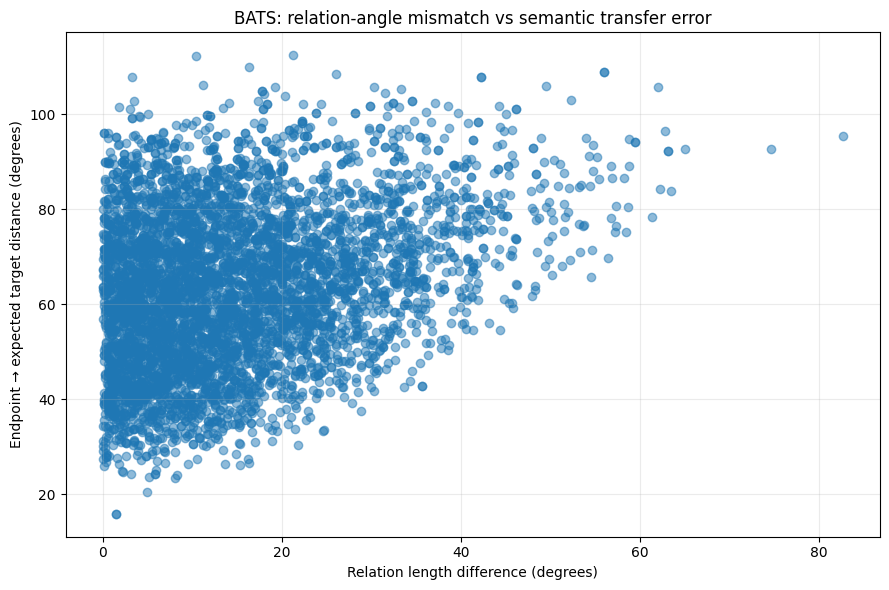

In [25]:
# ============================================================
# Angle mismatch analysis
# ============================================================

import matplotlib.pyplot as plt

if len(bats_transport_df) > 1:
    x = bats_transport_df[
        "relation_length_difference_deg"
    ].to_numpy()

    y = bats_transport_df[
        "distance_endpoint_to_target_deg"
    ].to_numpy()

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    if valid.sum() >= 2:
        correlation = (
            np.corrcoef(
                x[valid],
                y[valid],
            )[0, 1]
        )

        print(
            "Correlation between relation-length mismatch "
            "and endpoint-target error:",
            f"{correlation:.4f}",
        )

    plt.figure(
        figsize=(9, 6)
    )

    plt.scatter(
        x[valid],
        y[valid],
        alpha=0.5,
    )

    plt.xlabel(
        "Relation length difference (degrees)"
    )

    plt.ylabel(
        "Endpoint → expected target distance (degrees)"
    )

    plt.title(
        "BATS: relation-angle mismatch vs semantic transfer error"
    )

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


## 24. Interpretazione

BATS permette di valutare il transport su un benchmark molto più ampio e strutturato rispetto ai test manuali.

L'interpretazione rimane la stessa:

\[
\boxed{
\text{Parallel Transport preserves geometry}
}
\]

ma la conservazione semantica richiede che la relazione target reale sia compatibile sia in lunghezza sia, soprattutto, in direzione tangenziale.

Il confronto tra macro-categorie BATS permette inoltre di verificare se relazioni morfologiche, enciclopediche o lessicali possiedono livelli diversi di transferability nello spazio sferico.


## 25. Test mirato: trasporto della relazione paese → capitale

Questo modulo verifica in modo diretto se una relazione paese-capitale appresa in un punto della sfera può essere riutilizzata in un altro punto.

Esempio principale:

\[
\text{Italy}\rightarrow\text{Rome}
\quad\Longrightarrow\quad
\text{France}\rightarrow ?
\]

Il procedimento geometrico è:

1. estrarre nel punto `italy` il vettore tangente della relazione:

\[
v_{IT\to RO}=\log_{z_{italy}}(z_{rome});
\]

2. trasportarlo parallelamente dal punto `italy` al punto `france`:

\[
\tilde v=PT_{z_{italy}\to z_{france}}(v_{IT\to RO});
\]

3. partire da `france` e applicare la Exp-map:

\[
\hat z=\operatorname{Exp}_{z_{france}}(\tilde v);
\]

4. ordinare tutte le parole in base alla distanza angolare da \(\hat z\) e controllare il rank di `paris`.

La tabella `baseline_neighbors` mostra invece i vicini del solo punto `france`, prima del movimento. In questo modo possiamo distinguere l'effetto del trasporto dalla semplice vicinanza semantica tra Francia e Parigi.


In [26]:
# ============================================================
# Country -> capital: one detailed transport test
# ============================================================

def country_capital_transport_test(
    source_country,
    source_capital,
    target_country,
    expected_capital,
    top_k=10,
):
    result = test_relation_transport(
        source_country,
        source_capital,
        target_country,
        expected_capital,
        top_k=top_k,
    )

    target_country_vector = get_word_latent(target_country)

    baseline_neighbors = nearest_words_to_vector(
        target_country_vector,
        top_k=top_k,
        exclude_words=[
            source_country,
            source_capital,
            target_country,
        ],
    )

    baseline_rank, _ = rank_of_target(
        target_country_vector,
        expected_capital,
        exclude_words=[
            source_country,
            source_capital,
            target_country,
        ],
    )

    summary = dict(result["summary"])
    summary.update({
        "expected_capital": expected_capital,
        "rank_before_transport": int(baseline_rank),
        "rank_after_transport": int(summary["target_rank"]),
        "rank_improvement": int(
            baseline_rank - summary["target_rank"]
        ),
        f"expected_capital_in_top{top_k}": bool(
            summary["target_rank"] <= top_k
        ),
    })

    return {
        "summary": summary,
        "baseline_neighbors": baseline_neighbors,
        "transported_endpoint_neighbors": result["neighbors"],
        "endpoint": result["endpoint"],
    }


italy_france_test = country_capital_transport_test(
    source_country="italy",
    source_capital="rome",
    target_country="france",
    expected_capital="paris",
    top_k=10,
)

print("RIASSUNTO: Italy -> Rome trasportato su France")
display(pd.DataFrame([italy_france_test["summary"]]))

print("\nVICINI DI FRANCE PRIMA DEL TRASPORTO")
display(italy_france_test["baseline_neighbors"])

print("\nVICINI DELL'ENDPOINT DOPO IL TRASPORTO")
display(italy_france_test["transported_endpoint_neighbors"])

paris_rank = italy_france_test["summary"]["rank_after_transport"]
print(
    f"\nParis rank dopo il trasporto: {paris_rank}. "
    f"Paris è nella Top-10: {paris_rank <= 10}."
)


RIASSUNTO: Italy -> Rome trasportato su France


,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,transported_norm_error,direction_error_deg,distance_c_to_target_before_deg,distance_endpoint_to_target_deg,distance_improvement_deg,target_rank,target_cosine_similarity,top1_correct,top5_correct,expected_capital,rank_before_transport,rank_after_transport,rank_improvement,expected_capital_in_top10
0,italy→rome,france→paris,38.326338,34.923603,3.402735,0.0,69.779216,34.923603,40.010583,-5.08698,53,0.765926,False,False,paris,20,53,-33,False



VICINI DI FRANCE PRIMA DEL TRASPORTO


,rank,word,cosine_similarity,angle_deg
0,1,spain,0.942200,19.575652
1,2,russia,0.885396,27.699738
2,3,germany,0.882353,28.072512
3,4,prussia,0.866650,29.928292
4,5,sweden,0.865614,30.047060
5,6,poland,0.863525,30.285261
6,7,hungary,0.858106,30.895424
7,8,portugal,0.854891,31.252271
8,9,switzerland,0.852365,31.530108
9,10,denmark,0.842986,32.543183



VICINI DELL'ENDPOINT DOPO IL TRASPORTO


,rank,word,cosine_similarity,angle_deg
0,1,jerusalem,0.875883,28.850351
1,2,constantinople,0.861162,30.552641
2,3,theodosius,0.855441,31.191519
3,4,milan,0.850272,31.758758
4,5,england,0.847223,32.089055
5,6,edessa,0.847068,32.105761
6,7,wessex,0.830398,33.860393
7,8,venice,0.828819,34.022416
8,9,augustus,0.824353,34.477081
9,10,justinian,0.821176,34.797272



Paris rank dopo il trasporto: 53. Paris è nella Top-10: False.


### Come leggere il risultato

- `rank_before_transport`: posizione di `paris` usando direttamente il punto `france`, senza applicare alcuna relazione;
- `rank_after_transport`: posizione di `paris` rispetto all'endpoint ottenuto dopo il trasporto;
- `rank_improvement > 0`: il trasporto ha migliorato la posizione di Parigi;
- `expected_capital_in_top10 = True`: Parigi è tra i dieci punti più vicini all'endpoint;
- `distance_improvement_deg > 0`: l'endpoint è geometricamente più vicino a Parigi rispetto al punto Francia iniziale;
- `direction_error_deg`: differenza tra la direzione trasportata e la vera direzione `france → paris`;
- `transported_norm_error`: controllo puramente geometrico; deve essere circa zero perché il Parallel Transport conserva la lunghezza del vettore.

È possibile che `transported_norm_error` sia quasi zero ma che `paris` non sia nella Top-10: in quel caso il trasporto è matematicamente corretto, ma le due relazioni non sono rappresentate con la stessa direzione semantica nello spazio appreso.


## 26. Test incrociato su più relazioni paese → capitale

Il test seguente ripete lo stesso procedimento su più combinazioni. Ogni riga usa una relazione sorgente, per esempio `italy → rome`, e la trasporta su un nuovo paese, per esempio `germany`, controllando il rank della capitale attesa `berlin`.


In [27]:
# ============================================================
# Country -> capital: multiple cross-transfer tests
# ============================================================

COUNTRY_CAPITAL_PAIRS = [
    ("italy", "rome"),
    ("france", "paris"),
    ("germany", "berlin"),
    ("spain", "madrid"),
    ("portugal", "lisbon"),
    ("greece", "athens"),
    ("austria", "vienna"),
    ("russia", "moscow"),
]


def run_country_capital_cross_tests(pairs, top_k=10):
    rows = []
    skipped = []

    valid_pairs = [
        (country, capital)
        for country, capital in pairs
        if word_has_valid_latent(country)
        and word_has_valid_latent(capital)
    ]

    for source_country, source_capital in valid_pairs:
        for target_country, expected_capital in valid_pairs:
            if source_country == target_country:
                continue

            try:
                result = country_capital_transport_test(
                    source_country,
                    source_capital,
                    target_country,
                    expected_capital,
                    top_k=top_k,
                )

                row = dict(result["summary"])
                row.update({
                    "source_relation": (
                        f"{source_country}→{source_capital}"
                    ),
                    "target_test": (
                        f"{target_country}→{expected_capital}"
                    ),
                })
                rows.append(row)

            except Exception as error:
                skipped.append({
                    "source_relation": (
                        f"{source_country}→{source_capital}"
                    ),
                    "target_test": (
                        f"{target_country}→{expected_capital}"
                    ),
                    "reason": str(error),
                })

    return pd.DataFrame(rows), pd.DataFrame(skipped)


country_capital_cross_df, country_capital_skipped_df = (
    run_country_capital_cross_tests(
        COUNTRY_CAPITAL_PAIRS,
        top_k=10,
    )
)

columns_to_show = [
    "source_relation",
    "target_test",
    "rank_before_transport",
    "rank_after_transport",
    "rank_improvement",
    "expected_capital_in_top10",
    "distance_improvement_deg",
    "direction_error_deg",
    "transported_norm_error",
]

display(
    country_capital_cross_df[
        columns_to_show
    ].sort_values(
        [
            "expected_capital_in_top10",
            "rank_after_transport",
        ],
        ascending=[False, True],
    )
)

print("Test completati:", len(country_capital_cross_df))
print("Test saltati:", len(country_capital_skipped_df))


,source_relation,target_test,rank_before_transport,rank_after_transport,rank_improvement,expected_capital_in_top10,distance_improvement_deg,direction_error_deg,transported_norm_error
8,france→paris,germany→berlin,5,1,4,True,3.541930,53.195445,0.000000e+00
12,france→paris,austria→vienna,32,1,31,True,15.280827,41.018491,0.000000e+00
13,france→paris,russia→moscow,8,1,7,True,10.365636,42.536265,0.000000e+00
15,germany→berlin,france→paris,20,1,19,True,6.105357,53.195445,0.000000e+00
35,greece→athens,italy→rome,34,1,33,True,0.179312,68.103763,0.000000e+00
37,greece→athens,germany→berlin,6,1,5,True,0.093180,62.548523,0.000000e+00
43,austria→vienna,france→paris,20,1,19,True,9.525260,41.018491,0.000000e+00
50,russia→moscow,france→paris,20,1,19,True,11.192269,42.536265,0.000000e+00
55,russia→moscow,austria→vienna,32,1,31,True,7.022925,55.991692,0.000000e+00
20,germany→berlin,russia→moscow,8,2,6,True,-1.249662,67.219860,0.000000e+00


Test completati: 56
Test saltati: 0


In [28]:
# ============================================================
# Aggregate summary for country -> capital transfer
# ============================================================

if len(country_capital_cross_df) > 0:
    country_capital_summary = pd.DataFrame([{
        "n_tests": len(country_capital_cross_df),
        "top1_accuracy": float(
            country_capital_cross_df["top1_correct"].mean()
        ),
        "top5_accuracy": float(
            country_capital_cross_df["top5_correct"].mean()
        ),
        "top10_accuracy": float(
            country_capital_cross_df[
                "expected_capital_in_top10"
            ].mean()
        ),
        "fraction_rank_improved": float(
            (
                country_capital_cross_df["rank_improvement"] > 0
            ).mean()
        ),
        "median_rank_before": float(
            country_capital_cross_df[
                "rank_before_transport"
            ].median()
        ),
        "median_rank_after": float(
            country_capital_cross_df[
                "rank_after_transport"
            ].median()
        ),
        "mean_distance_improvement_deg": float(
            country_capital_cross_df[
                "distance_improvement_deg"
            ].mean()
        ),
        "mean_direction_error_deg": float(
            country_capital_cross_df[
                "direction_error_deg"
            ].mean()
        ),
        "max_transport_norm_error": float(
            country_capital_cross_df[
                "transported_norm_error"
            ].max()
        ),
    }])

    display(country_capital_summary)


,n_tests,top1_accuracy,top5_accuracy,top10_accuracy,fraction_rank_improved,median_rank_before,median_rank_after,mean_distance_improvement_deg,mean_direction_error_deg,max_transport_norm_error
0,56,0.160714,0.285714,0.321429,0.535714,26.0,26.5,-3.895705,68.281249,1.110223e-16


File BATS E01 utilizzato:
/kaggle/input/datasets/pancisaigo/bats-country/BATS_3.0/3_Encyclopedic_semantics/E01_country_capital.txt
Numero di coppie lette: 50

COPPIE BATS ORIGINALI


,capitale_originale,paese_originale
0,abuja,nigeria
1,amman,jordan
2,ankara,turkey
3,athens,greece
4,baghdad,iraq
5,bangkok,thailand
6,beijing,china
7,beirut,lebanon
8,belgrade,serbia
9,berlin,germany



COPPIE BATS NON DISPONIBILI NEL LATENT VOCABULARY


,capitale_BATS,paese_BATS,capitale_risolta,paese_risolto
0,abuja,nigeria,None,nigeria
1,bangkok,thailand,None,thailand
2,bucharest,romania,None,romania
3,conakry,guinea,None,guinea
4,havana,cuba,None,cuba
5,islamabad,pakistan,None,pakistan
6,taipei,taiwan,None,taiwan



PAROLE MANCANTI


...

Relazione sorgente: Rome → Italy
Trasportata sulla capitale: Paris
Paese atteso: France
Rank prima del transport: 5
Rank dopo il transport: 1
Miglioramento del rank: +4
Presente nella Top-10: True

VICINI DELL'ENDPOINT DOPO IL TRANSPORT


,posizione_top_k,rank,word,cosine_similarity,angle_deg,parola,è_paese_BATS,è_paese_corretto,tipo
0,1,1,france,0.821141,34.800873,france,True,True,paese corretto
1,2,2,switzerland,0.818748,35.040334,switzerland,True,False,altro paese
2,3,3,germany,0.770895,39.565635,germany,True,False,altro paese
3,4,4,moscow,0.755820,40.902939,moscow,False,False,altra parola
4,5,5,berlin,0.755162,40.960514,berlin,False,False,altra parola
5,6,6,liechtenstein,0.754454,41.022285,liechtenstein,False,False,altra parola
6,7,7,korea,0.753377,41.116218,korea,False,False,altra parola
7,8,8,kyrgyzstan,0.746384,41.721850,kyrgyzstan,False,False,altra parola
8,9,9,japan,0.742548,42.051064,japan,True,False,altro paese
9,10,10,sweden,0.742218,42.079335,sweden,True,False,altro paese



PAESI BATS PRESENTI NELLA TOP-10


,posizione_top_k,parola,è_paese_corretto
0,1,france,True
1,2,switzerland,False
2,3,germany,False
8,9,japan,False
9,10,sweden,False



✓ France è alla posizione 1 della Top-10.


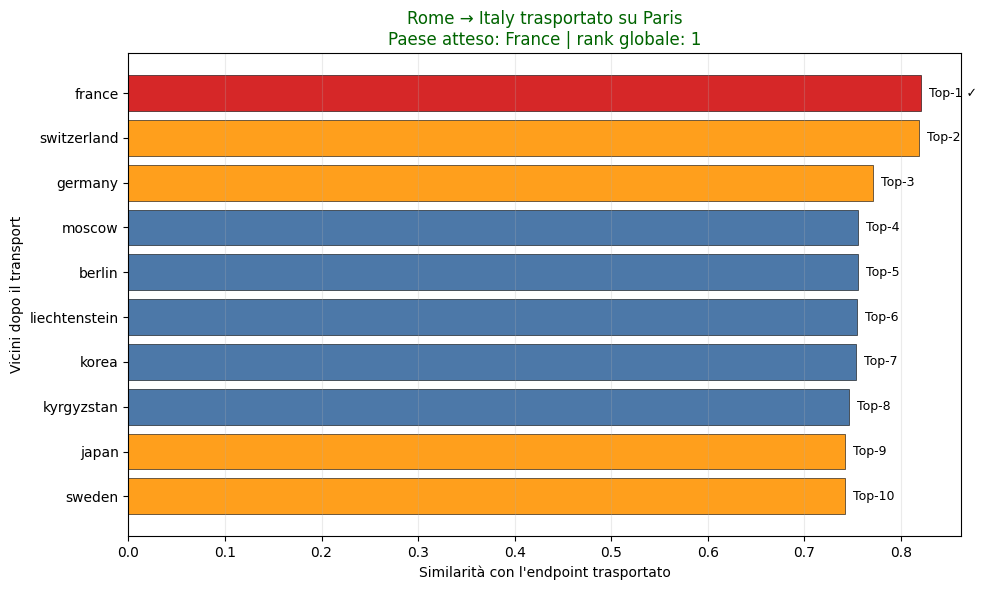

Output()


RISULTATI ORDINATI PER RANK DOPO IL TRANSPORT


,source_relation,target_test,rank_before_transport,rank_after_transport,rank_improvement,expected_country_in_top10,paesi_nella_top_k,status
73,ankara→turkey,paris→france,5,1,4,True,"france (Top-1), russia (Top-2), spain (Top-3),...",OK
69,ankara→turkey,moscow→russia,2,1,1,True,"russia (Top-1), ukraine (Top-4), austria (Top-...",OK
65,ankara→turkey,lisbon→portugal,16,1,15,True,"portugal (Top-1), jamaica (Top-5), spain (Top-9)",OK
48,ankara→turkey,berlin→germany,1,1,0,True,"germany (Top-1), russia (Top-2), austria (Top-...",OK
1385,paris→france,zagreb→croatia,6,1,5,True,"croatia (Top-1), serbia (Top-2), ukraine (Top-3)",OK
...,...,...,...,...,...,...,...,...
22,amman→jordan,lima→peru,1806,7333,-5527,False,"lebanon (Top-5), poland (Top-6)",OK
652,dhaka→bangladesh,lima→peru,1807,7733,-5926,False,nessuno,OK
1493,sofia→bulgaria,lima→peru,1806,8222,-6416,False,sweden (Top-10),OK
643,dhaka→bangladesh,copenhagen→denmark,606,8466,-7860,False,nessuno,OK


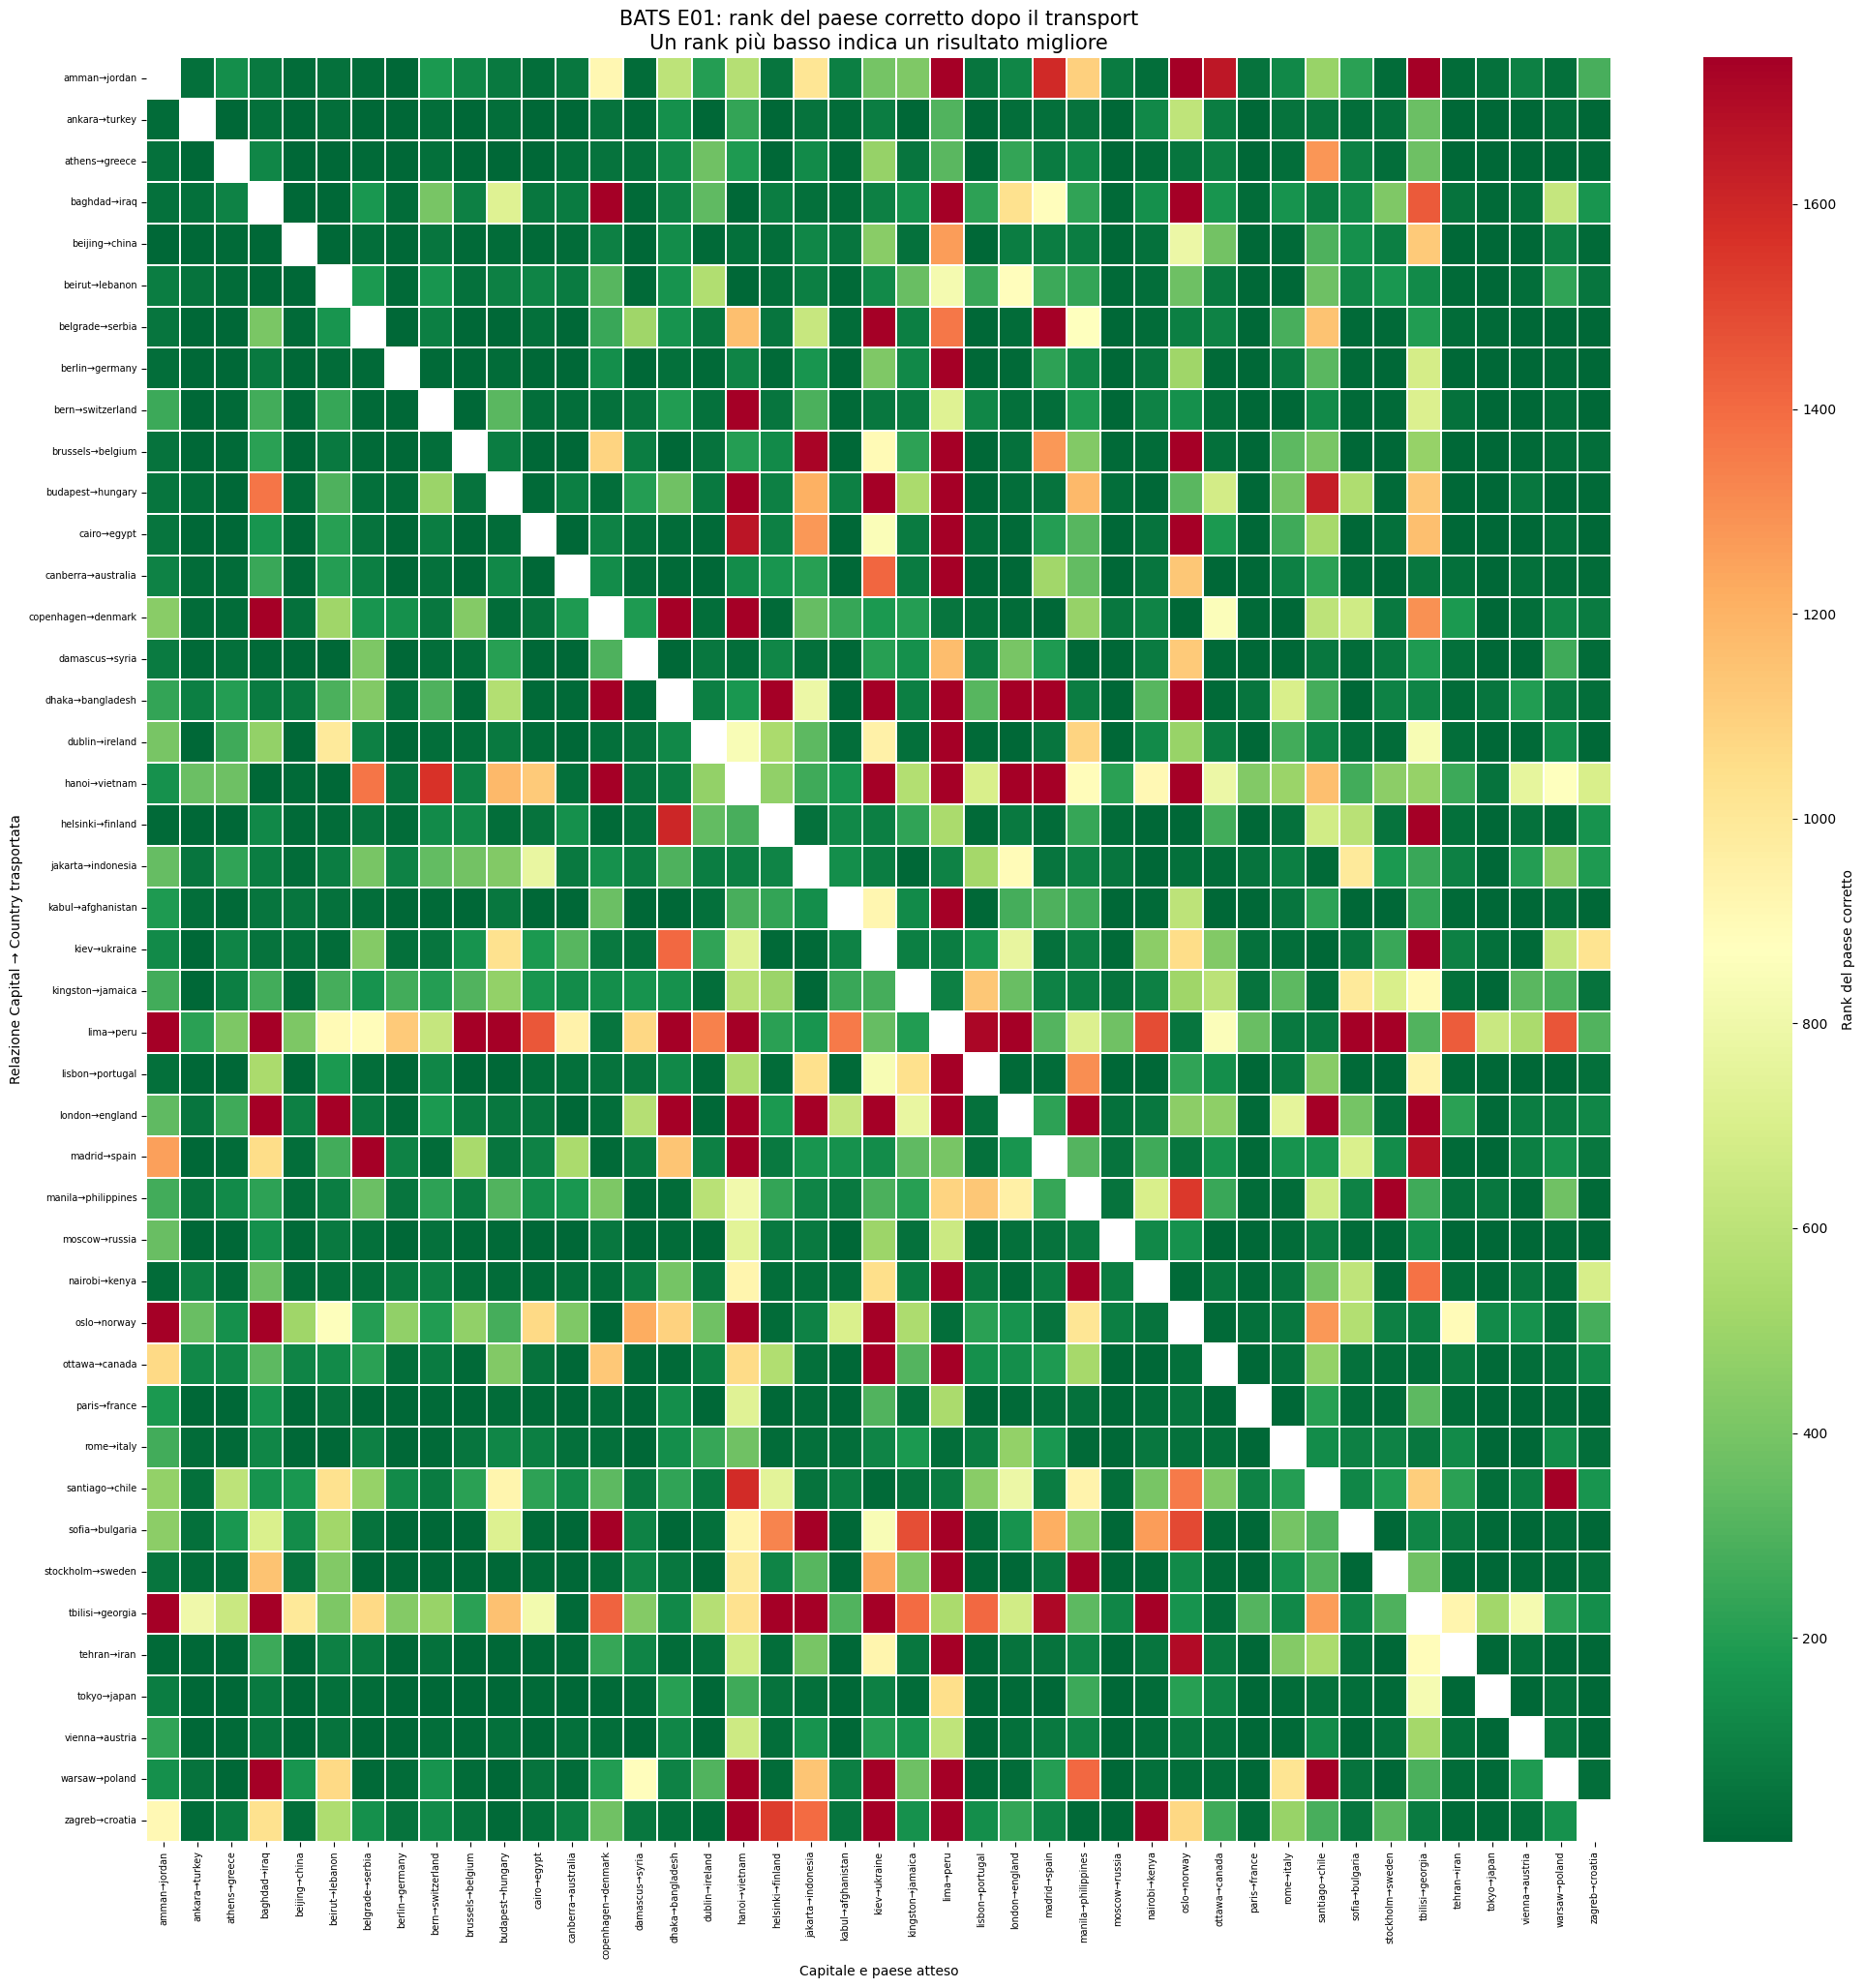

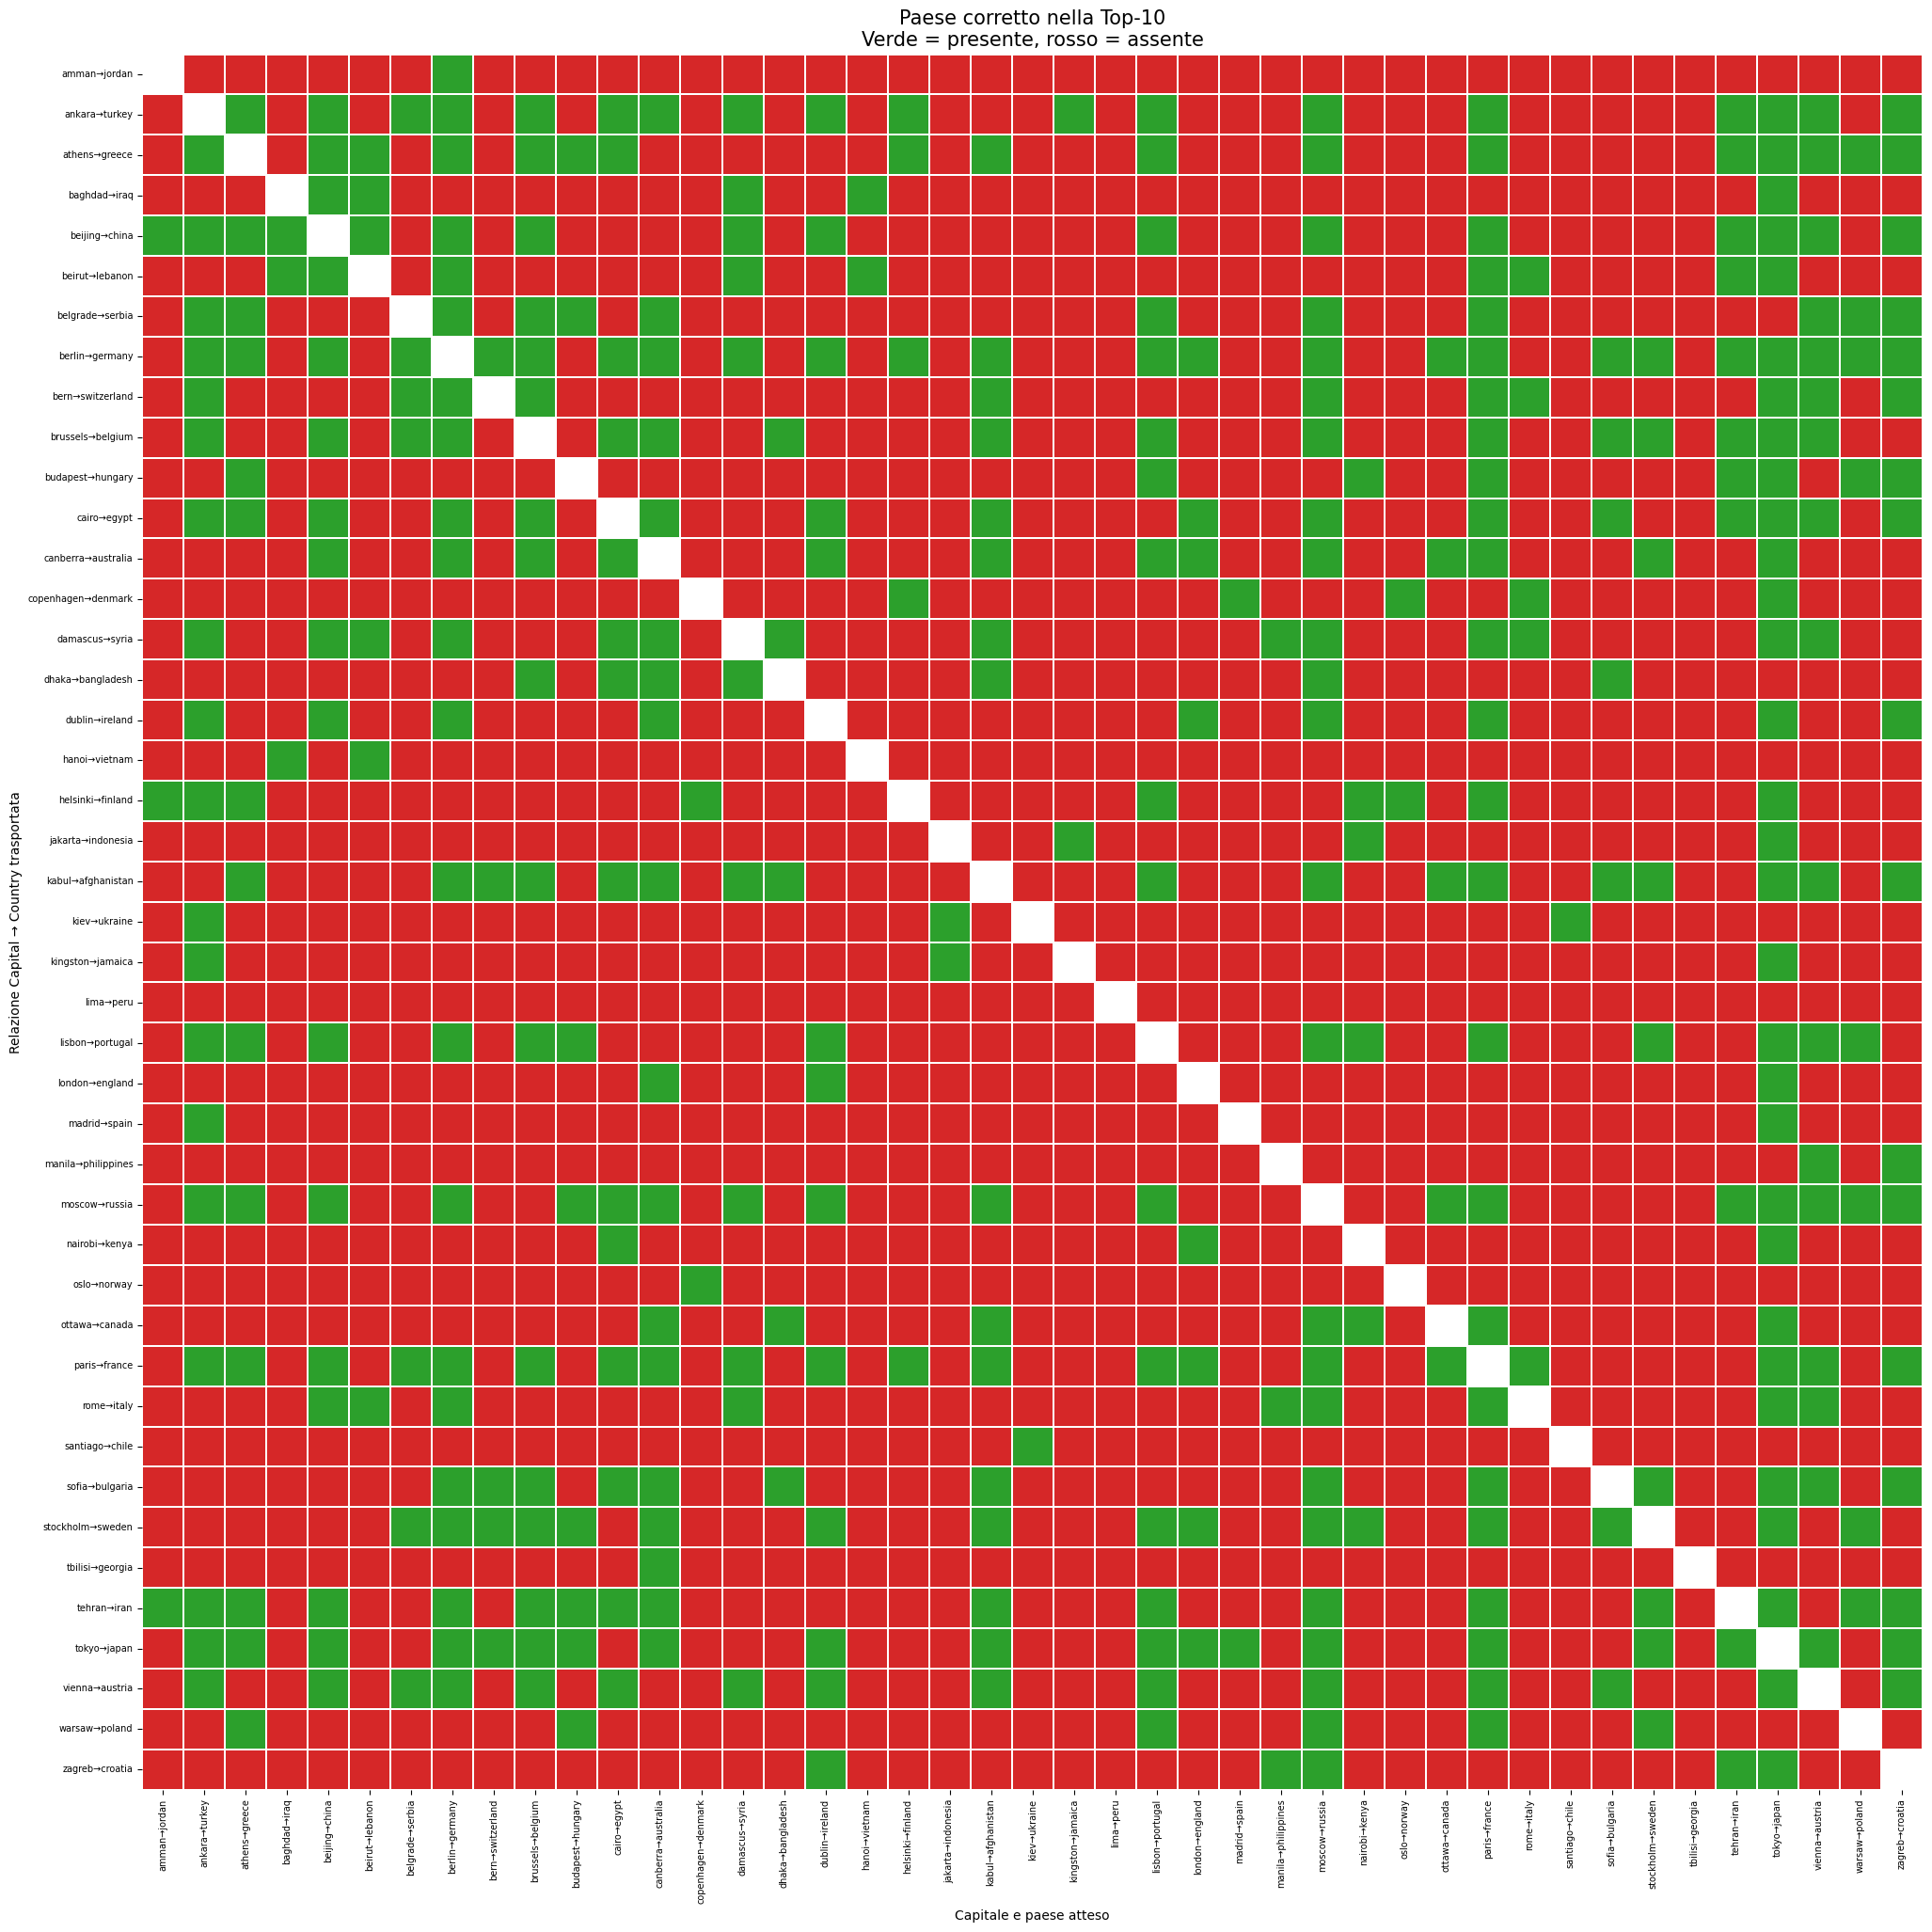


STATISTICHE GLOBALI


,coppie_BATS_originali,coppie_disponibili,coppie_escluse,test_previsti,test_completati,test_con_errore,top1_accuracy,top5_accuracy,top10_accuracy_before,top10_accuracy_after,...,rank_medio_prima,rank_medio_dopo,rank_mediano_prima,rank_mediano_dopo,miglioramento_medio,miglioramento_mediano,MRR_after,direction_error_medio_deg,distance_improvement_medio_deg,transported_norm_error_medio
0,50,43,7,1806,1806,0,0.063677,0.155039,0.255814,0.227021,...,416.557032,366.152824,39.0,67.0,50.404208,-1.0,0.119174,69.586907,-3.327108,2.698715e-17


In [ ]:
# ============================================================
# BATS E01: Capital -> Country
# Test completo di Relation Transport
#
# Il file BATS contiene:
# prima colonna  = capitale
# seconda colonna = paese
#
# Esempio:
# Rome -> Italy trasportato su Paris
# Target atteso: France
# ============================================================

from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display, clear_output

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


TOP_K = 10


# ============================================================
# 1. Test dettagliato Capital -> Country
# ============================================================

def capital_country_transport_test(
    source_capital,
    source_country,
    target_capital,
    expected_country,
    top_k=10,
):
    """
    Trasporta la relazione:

        source_capital -> source_country

    sulla capitale target_capital e verifica se
    expected_country è vicino all'endpoint.
    """

    result = test_relation_transport(
        source_capital,
        source_country,
        target_capital,
        expected_country,
        top_k=top_k,
    )

    target_capital_vector = get_word_latent(
        target_capital
    )

    excluded_words = [
        source_capital,
        source_country,
        target_capital,
    ]

    # Vicini della capitale target prima del transport
    baseline_neighbors = nearest_words_to_vector(
        target_capital_vector,
        top_k=top_k,
        exclude_words=excluded_words,
    )

    # Rank del paese corretto prima del transport
    baseline_rank, baseline_similarity = rank_of_target(
        target_capital_vector,
        expected_country,
        exclude_words=excluded_words,
    )

    summary = dict(result["summary"])

    rank_after_transport = int(
        summary["target_rank"]
    )

    summary.update({
        "source_relation": (
            f"{source_capital}→{source_country}"
        ),
        "target_test": (
            f"{target_capital}→{expected_country}"
        ),
        "expected_country": expected_country,
        "rank_before_transport": int(
            baseline_rank
        ),
        "rank_after_transport": (
            rank_after_transport
        ),
        "rank_improvement": int(
            baseline_rank
            - rank_after_transport
        ),
        "baseline_cosine_similarity": float(
            baseline_similarity
        ),
        f"expected_country_in_top{top_k}": bool(
            rank_after_transport <= top_k
        ),
    })

    return {
        "summary": summary,
        "baseline_neighbors": baseline_neighbors,
        "transported_endpoint_neighbors":
            result["neighbors"],
        "endpoint": result["endpoint"],
        "transported_vector":
            result.get("transported_vector"),
        "true_relation_vector":
            result.get("true_relation_vector"),
    }


# ============================================================
# 2. Ricerca automatica del file BATS E01
# ============================================================

def find_bats_capital_country_file():
    search_roots = [
        Path("/kaggle/input"),
        Path("."),
    ]

    patterns = [
        "**/E01_country_capital.txt",
        "**/E01*country*capital*.txt",
        "**/E01*.txt",
    ]

    candidates = []

    for root in search_roots:
        if not root.exists():
            continue

        for pattern in patterns:
            candidates.extend(
                root.glob(pattern)
            )

    candidates = list(
        dict.fromkeys(candidates)
    )

    if not candidates:
        raise FileNotFoundError(
            "File BATS E01 non trovato. "
            "Controllare il percorso del dataset."
        )

    candidates.sort(
        key=lambda path: (
            path.name
            != "E01_country_capital.txt",
            "country" not in path.name.lower(),
            "capital" not in path.name.lower(),
            len(str(path)),
        )
    )

    return candidates[0]


BATS_E01_PATH = (
    find_bats_capital_country_file()
)

print("File BATS E01 utilizzato:")
print(BATS_E01_PATH)


# ============================================================
# 3. Lettura delle coppie Capital -> Country
# ============================================================

def load_bats_capital_country_pairs(
    file_path,
):
    """
    Il file BATS E01 usa l'ordine:

        capitale TAB paese
    """

    raw_pairs = []

    with open(
        file_path,
        "r",
        encoding="utf-8-sig",
    ) as file:

        for line_number, line in enumerate(
            file,
            start=1,
        ):
            line = line.strip()

            if not line:
                continue

            if line.startswith("#"):
                continue

            parts = line.split("\t")

            if len(parts) < 2:
                raise ValueError(
                    f"Formato non riconosciuto "
                    f"alla riga {line_number}: "
                    f"{line}"
                )

            # Prima colonna: capitale
            raw_capital = (
                parts[0]
                .strip()
                .lower()
            )

            # Seconda colonna: paese
            raw_country = (
                parts[1]
                .strip()
                .lower()
            )

            raw_pairs.append(
                (
                    raw_capital,
                    raw_country,
                )
            )

    print(
        f"Numero di coppie lette: "
        f"{len(raw_pairs)}"
    )

    if len(raw_pairs) != 50:
        print(
            "ATTENZIONE: BATS E01 dovrebbe "
            "contenere 50 coppie."
        )

    return raw_pairs


RAW_CAPITAL_COUNTRY_PAIRS = (
    load_bats_capital_country_pairs(
        BATS_E01_PATH
    )
)

raw_pairs_df = pd.DataFrame(
    RAW_CAPITAL_COUNTRY_PAIRS,
    columns=[
        "capitale_originale",
        "paese_originale",
    ],
)

print("\nCOPPIE BATS ORIGINALI")
display(raw_pairs_df)


# ============================================================
# 4. Risoluzione delle parole nel latent vocabulary
# ============================================================

def candidate_word_forms(text):
    """
    Prova forme alternative per:
    - parole multiple separate da '/';
    - parole composte;
    - underscore;
    - trattini.
    """

    alternatives = [
        alternative.strip().lower()
        for alternative in text.split("/")
        if alternative.strip()
    ]

    candidates = []

    for alternative in alternatives:
        possible_forms = [
            alternative,
            alternative.replace(" ", "_"),
            alternative.replace("-", "_"),
            alternative.replace(" ", "-"),
            alternative.replace(" ", ""),
        ]

        for form in possible_forms:
            if form not in candidates:
                candidates.append(form)

    return candidates


def word_is_available(word):
    try:
        latent_vector = get_word_latent(word)

        return latent_vector is not None

    except Exception:
        return False


def resolve_bats_word(raw_word):
    """
    Restituisce la prima forma disponibile
    nel latent vocabulary.
    """

    for candidate in candidate_word_forms(
        raw_word
    ):
        if word_is_available(candidate):
            return candidate

    return None


# ============================================================
# 5. Controllo delle coppie disponibili
# ============================================================

resolved_pairs = []
missing_pairs = []

for (
    raw_capital,
    raw_country,
) in RAW_CAPITAL_COUNTRY_PAIRS:

    resolved_capital = resolve_bats_word(
        raw_capital
    )

    resolved_country = resolve_bats_word(
        raw_country
    )

    if (
        resolved_capital is not None
        and resolved_country is not None
    ):
        resolved_pairs.append(
            (
                resolved_capital,
                resolved_country,
            )
        )

    else:
        missing_pairs.append({
            "capitale_BATS": raw_capital,
            "paese_BATS": raw_country,
            "capitale_risolta":
                resolved_capital,
            "paese_risolto":
                resolved_country,
        })


if missing_pairs:
    print(
        "\nCOPPIE BATS NON DISPONIBILI "
        "NEL LATENT VOCABULARY"
    )

    missing_pairs_df = pd.DataFrame(
        missing_pairs
    )

    display(missing_pairs_df)

    missing_words = []

    for item in missing_pairs:
        if item["capitale_risolta"] is None:
            missing_words.append({
                "tipo": "capitale",
                "parola_BATS":
                    item["capitale_BATS"],
            })

        if item["paese_risolto"] is None:
            missing_words.append({
                "tipo": "paese",
                "parola_BATS":
                    item["paese_BATS"],
            })

    missing_words_df = (
        pd.DataFrame(missing_words)
        .drop_duplicates()
        .reset_index(drop=True)
    )

    print("\nPAROLE MANCANTI")
    display(missing_words_df)

    print(
        f"Coppie originali: "
        f"{len(RAW_CAPITAL_COUNTRY_PAIRS)}"
    )

    print(
        f"Coppie utilizzabili: "
        f"{len(resolved_pairs)}"
    )

    print(
        f"Coppie escluse: "
        f"{len(missing_pairs)}"
    )

    print(
        "\nI test continueranno usando "
        "soltanto le coppie disponibili."
    )

else:
    print(
        "\nTutte le 50 coppie BATS sono "
        "disponibili."
    )


AVAILABLE_CAPITAL_COUNTRY_PAIRS = (
    resolved_pairs
)

if len(AVAILABLE_CAPITAL_COUNTRY_PAIRS) < 2:
    raise RuntimeError(
        "Sono necessarie almeno due coppie "
        "valide per eseguire il transport."
    )


ALL_BATS_COUNTRIES = {
    country
    for _, country
    in AVAILABLE_CAPITAL_COUNTRY_PAIRS
}

NUMBER_OF_VALID_PAIRS = len(
    AVAILABLE_CAPITAL_COUNTRY_PAIRS
)

NUMBER_OF_TESTS = (
    NUMBER_OF_VALID_PAIRS
    * (NUMBER_OF_VALID_PAIRS - 1)
)

print("\n" + "=" * 70)
print("CONFIGURAZIONE FINALE")
print("=" * 70)

print(
    f"Coppie Capital → Country disponibili: "
    f"{NUMBER_OF_VALID_PAIRS}"
)

print(
    f"Numero di test direzionali: "
    f"{NUMBER_OF_VALID_PAIRS} × "
    f"{NUMBER_OF_VALID_PAIRS - 1} "
    f"= {NUMBER_OF_TESTS}"
)

available_pairs_df = pd.DataFrame(
    AVAILABLE_CAPITAL_COUNTRY_PAIRS,
    columns=[
        "capitale",
        "paese",
    ],
)

display(available_pairs_df)


# ============================================================
# 6. Preparazione della lista dei vicini
# ============================================================

def prepare_transported_neighbors(
    neighbors,
    expected_country,
):
    if isinstance(neighbors, pd.DataFrame):
        table = neighbors.copy()
    else:
        table = pd.DataFrame(neighbors)

    table = table.reset_index(drop=True)

    possible_word_columns = [
        "word",
        "parola",
        "neighbor",
        "nearest_word",
        "token",
    ]

    word_column = None

    for column in possible_word_columns:
        if column in table.columns:
            word_column = column
            break

    if word_column is None:
        word_column = table.columns[0]

    table.insert(
        0,
        "posizione_top_k",
        np.arange(
            1,
            len(table) + 1,
        ),
    )

    table["parola"] = (
        table[word_column]
        .astype(str)
        .str.lower()
    )

    # La parola è uno dei paesi BATS?
    table["è_paese_BATS"] = (
        table["parola"].isin(
            ALL_BATS_COUNTRIES
        )
    )

    # La parola è il paese corretto?
    table["è_paese_corretto"] = (
        table["parola"]
        == expected_country.lower()
    )

    table["tipo"] = "altra parola"

    table.loc[
        table["è_paese_BATS"],
        "tipo",
    ] = "altro paese"

    table.loc[
        table["è_paese_corretto"],
        "tipo",
    ] = "paese corretto"

    return table


# ============================================================
# 7. Creazione di tutti i test direzionali
# ============================================================

test_pairs = [
    (
        source_capital,
        source_country,
        target_capital,
        expected_country,
    )
    for (
        source_capital,
        source_country,
    ) in AVAILABLE_CAPITAL_COUNTRY_PAIRS
    for (
        target_capital,
        expected_country,
    ) in AVAILABLE_CAPITAL_COUNTRY_PAIRS
    if source_capital != target_capital
]

print(
    f"Test preparati: "
    f"{len(test_pairs)}"
)


# ============================================================
# 8. Esecuzione di tutti i test
# ============================================================

ALL_TRANSPORT_RESULTS = {}
ALL_TRANSPORT_NEIGHBORS = {}

summary_rows = []


for (
    source_capital,
    source_country,
    target_capital,
    expected_country,
) in tqdm(
    test_pairs,
    total=len(test_pairs),
    desc="Test Capital → Country",
):

    test_key = (
        source_capital,
        source_country,
        target_capital,
        expected_country,
    )

    try:
        result = capital_country_transport_test(
            source_capital=source_capital,
            source_country=source_country,
            target_capital=target_capital,
            expected_country=expected_country,
            top_k=TOP_K,
        )

        neighbor_table = (
            prepare_transported_neighbors(
                result[
                    "transported_endpoint_neighbors"
                ],
                expected_country=expected_country,
            )
        )

        countries_found = neighbor_table.loc[
            neighbor_table["è_paese_BATS"],
            [
                "posizione_top_k",
                "parola",
            ],
        ]

        countries_found_text = ", ".join(
            (
                f"{row.parola} "
                f"(Top-{int(row.posizione_top_k)})"
            )
            for row
            in countries_found.itertuples()
        )

        if not countries_found_text:
            countries_found_text = "nessuno"

        summary = result["summary"]

        rank_before = int(
            summary["rank_before_transport"]
        )

        rank_after = int(
            summary["rank_after_transport"]
        )

        rank_improvement = int(
            summary["rank_improvement"]
        )

        summary_rows.append({
            "source_capital":
                source_capital,

            "source_country":
                source_country,

            "target_capital":
                target_capital,

            "expected_country":
                expected_country,

            "source_relation":
                f"{source_capital}→{source_country}",

            "target_test":
                f"{target_capital}→{expected_country}",

            "rank_before_transport":
                rank_before,

            "rank_after_transport":
                rank_after,

            "rank_improvement":
                rank_improvement,

            f"expected_country_in_top{TOP_K}":
                bool(rank_after <= TOP_K),

            "top1_correct":
                bool(rank_after == 1),

            "top5_correct":
                bool(rank_after <= 5),

            "paesi_nella_top_k":
                countries_found_text,

            "original_relation_angle_deg":
                summary.get(
                    "original_relation_angle_deg",
                    np.nan,
                ),

            "true_target_relation_angle_deg":
                summary.get(
                    "true_target_relation_angle_deg",
                    np.nan,
                ),

            "relation_length_difference_deg":
                summary.get(
                    "relation_length_difference_deg",
                    np.nan,
                ),

            "direction_error_deg":
                summary.get(
                    "direction_error_deg",
                    np.nan,
                ),

            "distance_improvement_deg":
                summary.get(
                    "distance_improvement_deg",
                    np.nan,
                ),

            "transported_norm_error":
                summary.get(
                    "transported_norm_error",
                    np.nan,
                ),

            "status": "OK",
        })

        ALL_TRANSPORT_RESULTS[
            test_key
        ] = result

        ALL_TRANSPORT_NEIGHBORS[
            test_key
        ] = neighbor_table

    except Exception as error:
        summary_rows.append({
            "source_capital":
                source_capital,

            "source_country":
                source_country,

            "target_capital":
                target_capital,

            "expected_country":
                expected_country,

            "source_relation":
                f"{source_capital}→{source_country}",

            "target_test":
                f"{target_capital}→{expected_country}",

            "status":
                f"ERRORE: {error}",
        })


ALL_TRANSPORT_RESULTS_DF = pd.DataFrame(
    summary_rows
)

SUCCESSFUL_RESULTS_DF = (
    ALL_TRANSPORT_RESULTS_DF[
        ALL_TRANSPORT_RESULTS_DF["status"]
        == "OK"
    ]
    .copy()
    .reset_index(drop=True)
)

FAILED_RESULTS_DF = (
    ALL_TRANSPORT_RESULTS_DF[
        ALL_TRANSPORT_RESULTS_DF["status"]
        != "OK"
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("ESECUZIONE COMPLETATA")
print("=" * 70)

print(
    f"Test completati correttamente: "
    f"{len(SUCCESSFUL_RESULTS_DF)}"
)

print(
    f"Test con errore: "
    f"{len(FAILED_RESULTS_DF)}"
)

columns_to_show = [
    "source_relation",
    "target_test",
    "rank_before_transport",
    "rank_after_transport",
    "rank_improvement",
    f"expected_country_in_top{TOP_K}",
    "paesi_nella_top_k",
    "status",
]

display(
    SUCCESSFUL_RESULTS_DF[
        columns_to_show
    ]
)

if len(FAILED_RESULTS_DF) > 0:
    print("\nTEST CON ERRORE")
    display(FAILED_RESULTS_DF)


# ============================================================
# 9. Visualizzazione di un singolo test
# ============================================================

def show_capital_country_result(
    source_capital,
    target_capital,
):
    source_capital = source_capital.lower()
    target_capital = target_capital.lower()

    source_pairs = [
        pair
        for pair
        in AVAILABLE_CAPITAL_COUNTRY_PAIRS
        if pair[0] == source_capital
    ]

    target_pairs = [
        pair
        for pair
        in AVAILABLE_CAPITAL_COUNTRY_PAIRS
        if pair[0] == target_capital
    ]

    if not source_pairs:
        print(
            f"Capitale sorgente non trovata: "
            f"{source_capital}"
        )
        return

    if not target_pairs:
        print(
            f"Capitale di destinazione non trovata: "
            f"{target_capital}"
        )
        return

    if source_capital == target_capital:
        print(
            "La capitale sorgente e quella di "
            "destinazione devono essere diverse."
        )
        return

    source_country = source_pairs[0][1]
    expected_country = target_pairs[0][1]

    test_key = (
        source_capital,
        source_country,
        target_capital,
        expected_country,
    )

    if test_key not in ALL_TRANSPORT_RESULTS:
        print(
            "Risultato non disponibile "
            "per questo test."
        )
        return

    result = ALL_TRANSPORT_RESULTS[
        test_key
    ]

    table = ALL_TRANSPORT_NEIGHBORS[
        test_key
    ].copy()

    summary = result["summary"]

    rank_before = int(
        summary["rank_before_transport"]
    )

    rank_after = int(
        summary["rank_after_transport"]
    )

    improvement = int(
        summary["rank_improvement"]
    )

    print("=" * 90)

    print(
        f"Relazione sorgente: "
        f"{source_capital.title()} → "
        f"{source_country.title()}"
    )

    print(
        f"Trasportata sulla capitale: "
        f"{target_capital.title()}"
    )

    print(
        f"Paese atteso: "
        f"{expected_country.title()}"
    )

    print(
        f"Rank prima del transport: "
        f"{rank_before}"
    )

    print(
        f"Rank dopo il transport: "
        f"{rank_after}"
    )

    print(
        f"Miglioramento del rank: "
        f"{improvement:+d}"
    )

    print(
        f"Presente nella Top-{TOP_K}: "
        f"{rank_after <= TOP_K}"
    )

    print("=" * 90)

    def highlight_neighbor(row):
        if row["è_paese_corretto"]:
            style = (
                "background-color: #ffb3b3; "
                "font-weight: bold;"
            )

        elif row["è_paese_BATS"]:
            style = (
                "background-color: #ffe0a3;"
            )

        else:
            style = ""

        return [style] * len(row)

    print(
        f"\nVICINI DELL'ENDPOINT DOPO "
        f"IL TRANSPORT"
    )

    display(
        table.style.apply(
            highlight_neighbor,
            axis=1,
        )
    )

    countries_in_list = table.loc[
        table["è_paese_BATS"],
        [
            "posizione_top_k",
            "parola",
            "è_paese_corretto",
        ],
    ]

    print(
        f"\nPAESI BATS PRESENTI "
        f"NELLA TOP-{TOP_K}"
    )

    if len(countries_in_list) > 0:
        display(countries_in_list)
    else:
        print(
            "Nessun paese BATS presente."
        )

    if rank_after <= TOP_K:
        correct_rows = table.loc[
            table["è_paese_corretto"]
        ]

        if len(correct_rows) > 0:
            local_rank = int(
                correct_rows.iloc[0][
                    "posizione_top_k"
                ]
            )

            print(
                f"\n✓ {expected_country.title()} "
                f"è alla posizione {local_rank} "
                f"della Top-{TOP_K}."
            )

    else:
        print(
            f"\n✗ {expected_country.title()} "
            f"non è nella Top-{TOP_K}."
        )

        print(
            f"Rank nel vocabolario completo: "
            f"{rank_after}."
        )

    # --------------------------------------------------------
    # Grafico dei vicini
    # --------------------------------------------------------

    similarity_candidates = [
        "cosine_similarity",
        "similarity",
        "score",
        "sim",
    ]

    similarity_column = next(
        (
            column
            for column
            in similarity_candidates
            if column in table.columns
        ),
        None,
    )

    plot_table = table.copy()

    if similarity_column is None:
        plot_table[
            "valore_visualizzazione"
        ] = (
            len(plot_table)
            - plot_table["posizione_top_k"]
            + 1
        )

        similarity_column = (
            "valore_visualizzazione"
        )

    else:
        plot_table[
            similarity_column
        ] = pd.to_numeric(
            plot_table[similarity_column],
            errors="coerce",
        )

    colors = []

    for _, row in plot_table.iterrows():
        if row["è_paese_corretto"]:
            colors.append("#d62728")

        elif row["è_paese_BATS"]:
            colors.append("#ff9f1c")

        else:
            colors.append("#4c78a8")

    plot_table["colore"] = colors
    plot_table = plot_table.iloc[::-1]

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_table["parola"],
        plot_table[similarity_column],
        color=plot_table["colore"],
        edgecolor="black",
        linewidth=0.4,
    )

    for _, row in plot_table.iterrows():
        label = (
            f"Top-"
            f"{int(row['posizione_top_k'])}"
        )

        if row["è_paese_corretto"]:
            label += " ✓"

        plt.text(
            row[similarity_column],
            row["parola"],
            f"  {label}",
            va="center",
            fontsize=9,
        )

    title_color = (
        "darkgreen"
        if rank_after <= TOP_K
        else "darkred"
    )

    plt.title(
        f"{source_capital.title()} → "
        f"{source_country.title()} "
        f"trasportato su "
        f"{target_capital.title()}\n"
        f"Paese atteso: "
        f"{expected_country.title()} | "
        f"rank globale: {rank_after}",
        color=title_color,
    )

    if (
        similarity_column
        == "valore_visualizzazione"
    ):
        plt.xlabel(
            "Posizione relativa nella Top-K"
        )
    else:
        plt.xlabel(
            "Similarità con l'endpoint trasportato"
        )

    plt.ylabel(
        "Vicini dopo il transport"
    )

    plt.grid(
        axis="x",
        alpha=0.25,
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 10. Esempio: Rome -> Italy trasportato su Paris
# ============================================================

available_capitals = [
    capital
    for capital, _
    in AVAILABLE_CAPITAL_COUNTRY_PAIRS
]

if (
    "rome" in available_capitals
    and "paris" in available_capitals
):
    show_capital_country_result(
        source_capital="rome",
        target_capital="paris",
    )


# ============================================================
# 11. Selettore interattivo
# ============================================================

try:
    import ipywidgets as widgets

    capital_options = sorted(
        available_capitals
    )

    source_selector = widgets.Dropdown(
        options=capital_options,
        value=capital_options[0],
        description="Sorgente:",
        layout=widgets.Layout(
            width="350px"
        ),
    )

    target_selector = widgets.Dropdown(
        options=capital_options,
        value=capital_options[1],
        description="Destinazione:",
        layout=widgets.Layout(
            width="350px"
        ),
    )

    interactive_output = widgets.Output()

    def update_visualization(change=None):
        with interactive_output:
            clear_output(wait=True)

            show_capital_country_result(
                source_capital=(
                    source_selector.value
                ),
                target_capital=(
                    target_selector.value
                ),
            )

    source_selector.observe(
        update_visualization,
        names="value",
    )

    target_selector.observe(
        update_visualization,
        names="value",
    )

    display(
        widgets.HBox([
            source_selector,
            target_selector,
        ])
    )

    display(interactive_output)

    update_visualization()

except ImportError:
    print(
        "ipywidgets non disponibile. "
        "Usare show_capital_country_result()."
    )


# ============================================================
# 12. Risultati ordinati
# ============================================================

print(
    "\nRISULTATI ORDINATI PER "
    "RANK DOPO IL TRANSPORT"
)

display(
    SUCCESSFUL_RESULTS_DF[
        columns_to_show
    ].sort_values(
        by="rank_after_transport",
        ascending=True,
    )
)


# ============================================================
# 13. Heatmap del rank del paese corretto
# ============================================================

if len(SUCCESSFUL_RESULTS_DF) > 0:
    heatmap_df = (
        SUCCESSFUL_RESULTS_DF.copy()
    )

    rank_matrix = heatmap_df.pivot(
        index="source_relation",
        columns="target_test",
        values="rank_after_transport",
    )

    figure_size = max(
        14,
        NUMBER_OF_VALID_PAIRS * 0.48,
    )

    rank_values = (
        rank_matrix
        .to_numpy(dtype=float)
    )

    rank_vmax = np.nanpercentile(
        rank_values,
        95,
    )

    plt.figure(
        figsize=(
            figure_size,
            figure_size,
        )
    )

    sns.heatmap(
        rank_matrix,
        cmap="RdYlGn_r",
        vmin=1,
        vmax=rank_vmax,
        linewidths=0.15,
        linecolor="white",
        cbar_kws={
            "label":
                "Rank del paese corretto"
        },
    )

    plt.title(
        "BATS E01: rank del paese corretto "
        "dopo il transport\n"
        "Un rank più basso indica "
        "un risultato migliore",
        fontsize=15,
    )

    plt.xlabel(
        "Capitale e paese atteso"
    )

    plt.ylabel(
        "Relazione Capital → Country trasportata"
    )

    plt.xticks(
        rotation=90,
        fontsize=7,
    )

    plt.yticks(
        rotation=0,
        fontsize=7,
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 14. Heatmap Top-10
# ============================================================

if len(SUCCESSFUL_RESULTS_DF) > 0:
    top_k_column = (
        f"expected_country_in_top{TOP_K}"
    )

    top_k_matrix = heatmap_df.pivot(
        index="source_relation",
        columns="target_test",
        values=top_k_column,
    ).astype(float)

    plt.figure(
        figsize=(
            figure_size,
            figure_size,
        )
    )

    sns.heatmap(
        top_k_matrix,
        cmap=[
            "#d62728",
            "#2ca02c",
        ],
        vmin=0,
        vmax=1,
        linewidths=0.15,
        linecolor="white",
        cbar=False,
    )

    plt.title(
        f"Paese corretto nella Top-{TOP_K}\n"
        f"Verde = presente, rosso = assente",
        fontsize=15,
    )

    plt.xlabel(
        "Capitale e paese atteso"
    )

    plt.ylabel(
        "Relazione Capital → Country trasportata"
    )

    plt.xticks(
        rotation=90,
        fontsize=7,
    )

    plt.yticks(
        rotation=0,
        fontsize=7,
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 15. Statistiche globali
# ============================================================

if len(SUCCESSFUL_RESULTS_DF) > 0:
    rank_before = (
        SUCCESSFUL_RESULTS_DF[
            "rank_before_transport"
        ]
    )

    rank_after = (
        SUCCESSFUL_RESULTS_DF[
            "rank_after_transport"
        ]
    )

    rank_improvement = (
        SUCCESSFUL_RESULTS_DF[
            "rank_improvement"
        ]
    )

    global_summary = pd.DataFrame([{
        "coppie_BATS_originali":
            len(
                RAW_CAPITAL_COUNTRY_PAIRS
            ),

        "coppie_disponibili":
            NUMBER_OF_VALID_PAIRS,

        "coppie_escluse":
            len(missing_pairs),

        "test_previsti":
            NUMBER_OF_TESTS,

        "test_completati":
            len(
                SUCCESSFUL_RESULTS_DF
            ),

        "test_con_errore":
            len(
                FAILED_RESULTS_DF
            ),

        "top1_accuracy":
            float(
                (rank_after == 1).mean()
            ),

        "top5_accuracy":
            float(
                (rank_after <= 5).mean()
            ),

        f"top{TOP_K}_accuracy_before":
            float(
                (rank_before <= TOP_K).mean()
            ),

        f"top{TOP_K}_accuracy_after":
            float(
                (rank_after <= TOP_K).mean()
            ),

        "fraction_rank_improved":
            float(
                (rank_improvement > 0).mean()
            ),

        "fraction_rank_unchanged":
            float(
                (rank_improvement == 0).mean()
            ),

        "fraction_rank_worsened":
            float(
                (rank_improvement < 0).mean()
            ),

        "rank_medio_prima":
            float(rank_before.mean()),

        "rank_medio_dopo":
            float(rank_after.mean()),

        "rank_mediano_prima":
            float(rank_before.median()),

        "rank_mediano_dopo":
            float(rank_after.median()),

        "miglioramento_medio":
            float(rank_improvement.mean()),

        "miglioramento_mediano":
            float(rank_improvement.median()),

        "MRR_after":
            float(
                (1.0 / rank_after).mean()
            ),

        "direction_error_medio_deg":
            float(
                SUCCESSFUL_RESULTS_DF[
                    "direction_error_deg"
                ].mean()
            ),

        "distance_improvement_medio_deg":
            float(
                SUCCESSFUL_RESULTS_DF[
                    "distance_improvement_deg"
                ].mean()
            ),

        "transported_norm_error_medio":
            float(
                SUCCESSFUL_RESULTS_DF[
                    "transported_norm_error"
                ].mean()
            ),
    }])

    print("\nSTATISTICHE GLOBALI")
    display(global_summary)

In [30]:
# ============================================================
# 16. Selezione dei 10 test migliori e peggiori
# ============================================================

# Migliori:
# 1. rank dopo il transport più basso;
# 2. a parità di rank, miglioramento maggiore.

BEST_10_TESTS_DF = (
    SUCCESSFUL_RESULTS_DF
    .sort_values(
        by=[
            "rank_after_transport",
            "rank_improvement",
        ],
        ascending=[True, False],
    )
    .head(10)
    .copy()
    .reset_index(drop=True)
)

# Peggiori:
# 1. rank dopo il transport più alto;
# 2. a parità di rank, peggioramento maggiore.

WORST_10_TESTS_DF = (
    SUCCESSFUL_RESULTS_DF
    .sort_values(
        by=[
            "rank_after_transport",
            "rank_improvement",
        ],
        ascending=[False, True],
    )
    .head(10)
    .copy()
    .reset_index(drop=True)
)

BEST_10_TESTS_DF.insert(
    0,
    "posizione_selezione",
    np.arange(1, 11),
)

WORST_10_TESTS_DF.insert(
    0,
    "posizione_selezione",
    np.arange(1, 11),
)

selection_columns = [
    "posizione_selezione",
    "source_relation",
    "target_test",
    "rank_before_transport",
    "rank_after_transport",
    "rank_improvement",
]

print("10 TEST MIGLIORI")

display(
    BEST_10_TESTS_DF[
        selection_columns
    ]
)

print("\n10 TEST PEGGIORI")

display(
    WORST_10_TESTS_DF[
        selection_columns
    ]
)

10 TEST MIGLIORI


,posizione_selezione,source_relation,target_test,rank_before_transport,rank_after_transport,rank_improvement
0,1,copenhagen→denmark,oslo→norway,224,1,223
1,2,canberra→australia,london→england,179,1,178
2,3,athens→greece,beijing→china,62,1,61
3,4,beirut→lebanon,beijing→china,62,1,61
4,5,berlin→germany,beijing→china,62,1,61
5,6,damascus→syria,beijing→china,62,1,61
6,7,paris→france,beijing→china,62,1,61
7,8,tokyo→japan,beijing→china,62,1,61
8,9,ankara→turkey,beijing→china,61,1,60
9,10,damascus→syria,rome→italy,55,1,54



10 TEST PEGGIORI


,posizione_selezione,source_relation,target_test,rank_before_transport,rank_after_transport,rank_improvement
0,1,hanoi→vietnam,lima→peru,1806,8973,-7167
1,2,dhaka→bangladesh,copenhagen→denmark,606,8466,-7860
2,3,sofia→bulgaria,lima→peru,1806,8222,-6416
3,4,dhaka→bangladesh,lima→peru,1807,7733,-5926
4,5,amman→jordan,lima→peru,1806,7333,-5527
5,6,brussels→belgium,lima→peru,1806,7186,-5380
6,7,stockholm→sweden,lima→peru,1805,6855,-5050
7,8,amman→jordan,oslo→norway,224,6330,-6106
8,9,tbilisi→georgia,kiev→ukraine,4134,6095,-1961
9,10,warsaw→poland,lima→peru,1805,5771,-3966


In [31]:
# ============================================================
# 17. Funzioni per visualizzare la Top-10 dopo il transport
# ============================================================

from matplotlib.patches import Patch


def transport_key_from_row(row):
    return (
        row["source_capital"],
        row["source_country"],
        row["target_capital"],
        row["expected_country"],
    )


def transported_top10_from_row(row):
    """
    Recupera la Top-10 dell'endpoint trasportato.
    """

    test_key = transport_key_from_row(row)

    if test_key not in ALL_TRANSPORT_NEIGHBORS:
        raise KeyError(
            f"Risultato non disponibile: {test_key}"
        )

    table = (
        ALL_TRANSPORT_NEIGHBORS[
            test_key
        ]
        .copy()
        .head(TOP_K)
        .reset_index(drop=True)
    )

    if "posizione_top_k" not in table.columns:
        table.insert(
            0,
            "posizione_top_k",
            np.arange(1, len(table) + 1),
        )

    if "parola" not in table.columns:
        table["parola"] = (
            table["word"]
            .astype(str)
            .str.lower()
        )

    table["è_paese_BATS"] = (
        table["parola"].isin(
            ALL_BATS_COUNTRIES
        )
    )

    table["è_paese_corretto"] = (
        table["parola"]
        == str(
            row["expected_country"]
        ).lower()
    )

    table["tipo"] = "altra parola"

    table.loc[
        table["è_paese_BATS"],
        "tipo",
    ] = "altro paese BATS"

    table.loc[
        table["è_paese_corretto"],
        "tipo",
    ] = "paese corretto"

    return table


def build_selected_top10_table(
    selected_df,
    group_name,
):
    """
    Crea una tabella con i 10 vicini
    di ciascuno dei 10 test selezionati.
    """

    detail_rows = []

    for _, row in selected_df.iterrows():
        neighbor_table = (
            transported_top10_from_row(row)
        )

        for _, neighbor in neighbor_table.iterrows():
            detail_rows.append({
                "gruppo":
                    group_name,

                "test_n":
                    int(
                        row[
                            "posizione_selezione"
                        ]
                    ),

                "source_relation":
                    row["source_relation"],

                "target_test":
                    row["target_test"],

                "rank_target_globale":
                    int(
                        row[
                            "rank_after_transport"
                        ]
                    ),

                "posizione_top_k":
                    int(
                        neighbor[
                            "posizione_top_k"
                        ]
                    ),

                "parola":
                    neighbor["parola"],

                "cosine_similarity":
                    neighbor.get(
                        "cosine_similarity",
                        np.nan,
                    ),

                "tipo":
                    neighbor["tipo"],
            })

    return pd.DataFrame(detail_rows)


def highlight_selected_neighbor(row):
    """
    Rosso: paese corretto.
    Arancione: altro paese BATS.
    """

    if row["tipo"] == "paese corretto":
        style = (
            "background-color: #ffb3b3; "
            "font-weight: bold;"
        )

    elif row["tipo"] == "altro paese BATS":
        style = (
            "background-color: #ffe0a3;"
        )

    else:
        style = ""

    return [style] * len(row)


def plot_selected_transport_top10(
    selected_df,
    figure_title,
):
    """
    Visualizza i 10 test in una griglia 5 × 2.
    Ogni grafico mostra la Top-10
    dell'endpoint dopo il transport.
    """

    number_of_tests = len(selected_df)

    number_of_columns = 2

    number_of_rows = int(
        np.ceil(
            number_of_tests
            / number_of_columns
        )
    )

    figure, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(
            20,
            5.3 * number_of_rows,
        ),
    )

    axes = np.asarray(
        axes
    ).reshape(-1)

    for axis, (_, row) in zip(
        axes,
        selected_df.iterrows(),
    ):
        table = transported_top10_from_row(
            row
        )

        similarity_column = None

        for candidate in [
            "cosine_similarity",
            "similarity",
            "score",
            "sim",
        ]:
            if candidate in table.columns:
                similarity_column = candidate
                break

        if similarity_column is None:
            table[
                "valore_visualizzazione"
            ] = (
                len(table)
                - table["posizione_top_k"]
                + 1
            )

            similarity_column = (
                "valore_visualizzazione"
            )

        else:
            table[
                similarity_column
            ] = pd.to_numeric(
                table[similarity_column],
                errors="coerce",
            )

        colors = []

        for _, neighbor in table.iterrows():
            if neighbor["è_paese_corretto"]:
                colors.append("#d62728")

            elif neighbor["è_paese_BATS"]:
                colors.append("#ff9f1c")

            else:
                colors.append("#4c78a8")

        table["colore"] = colors

        # Inversione per mostrare Top-1 in alto
        plot_table = table.iloc[::-1].copy()

        labels = [
            f"{int(position)}. {word}"
            for position, word in zip(
                plot_table[
                    "posizione_top_k"
                ],
                plot_table["parola"],
            )
        ]

        axis.barh(
            labels,
            plot_table[
                similarity_column
            ],
            color=plot_table["colore"],
            edgecolor="black",
            linewidth=0.35,
        )

        rank_after = int(
            row["rank_after_transport"]
        )

        rank_improvement = int(
            row["rank_improvement"]
        )

        expected_country = str(
            row["expected_country"]
        )

        if rank_after <= TOP_K:
            top10_status = (
                "presente nella Top-10"
            )
            title_color = "darkgreen"

        else:
            top10_status = (
                "assente dalla Top-10"
            )
            title_color = "darkred"

        axis.set_title(
            f"{int(row['posizione_selezione'])}. "
            f"{row['source_relation']} "
            f"trasportato su "
            f"{row['target_capital'].title()}\n"
            f"Atteso: "
            f"{expected_country.title()} | "
            f"rank globale: {rank_after} | "
            f"Δrank: {rank_improvement:+d} | "
            f"{top10_status}",
            fontsize=10,
            color=title_color,
        )

        if (
            similarity_column
            == "valore_visualizzazione"
        ):
            axis.set_xlabel(
                "Posizione relativa nella Top-10"
            )
        else:
            axis.set_xlabel(
                "Similarità con "
                "l'endpoint trasportato"
            )

        axis.grid(
            axis="x",
            alpha=0.25,
        )

    # Nasconde eventuali assi inutilizzati
    for axis in axes[number_of_tests:]:
        axis.axis("off")

    legend_elements = [
        Patch(
            facecolor="#d62728",
            edgecolor="black",
            label="Paese corretto",
        ),
        Patch(
            facecolor="#ff9f1c",
            edgecolor="black",
            label="Altro paese BATS",
        ),
        Patch(
            facecolor="#4c78a8",
            edgecolor="black",
            label="Altra parola",
        ),
    ]

    figure.legend(
        handles=legend_elements,
        loc="upper center",
        ncol=3,
        bbox_to_anchor=(0.5, 0.985),
    )

    figure.suptitle(
        figure_title,
        fontsize=17,
        y=1.01,
    )

    figure.tight_layout(
        rect=[0, 0, 1, 0.97]
    )

    plt.show()

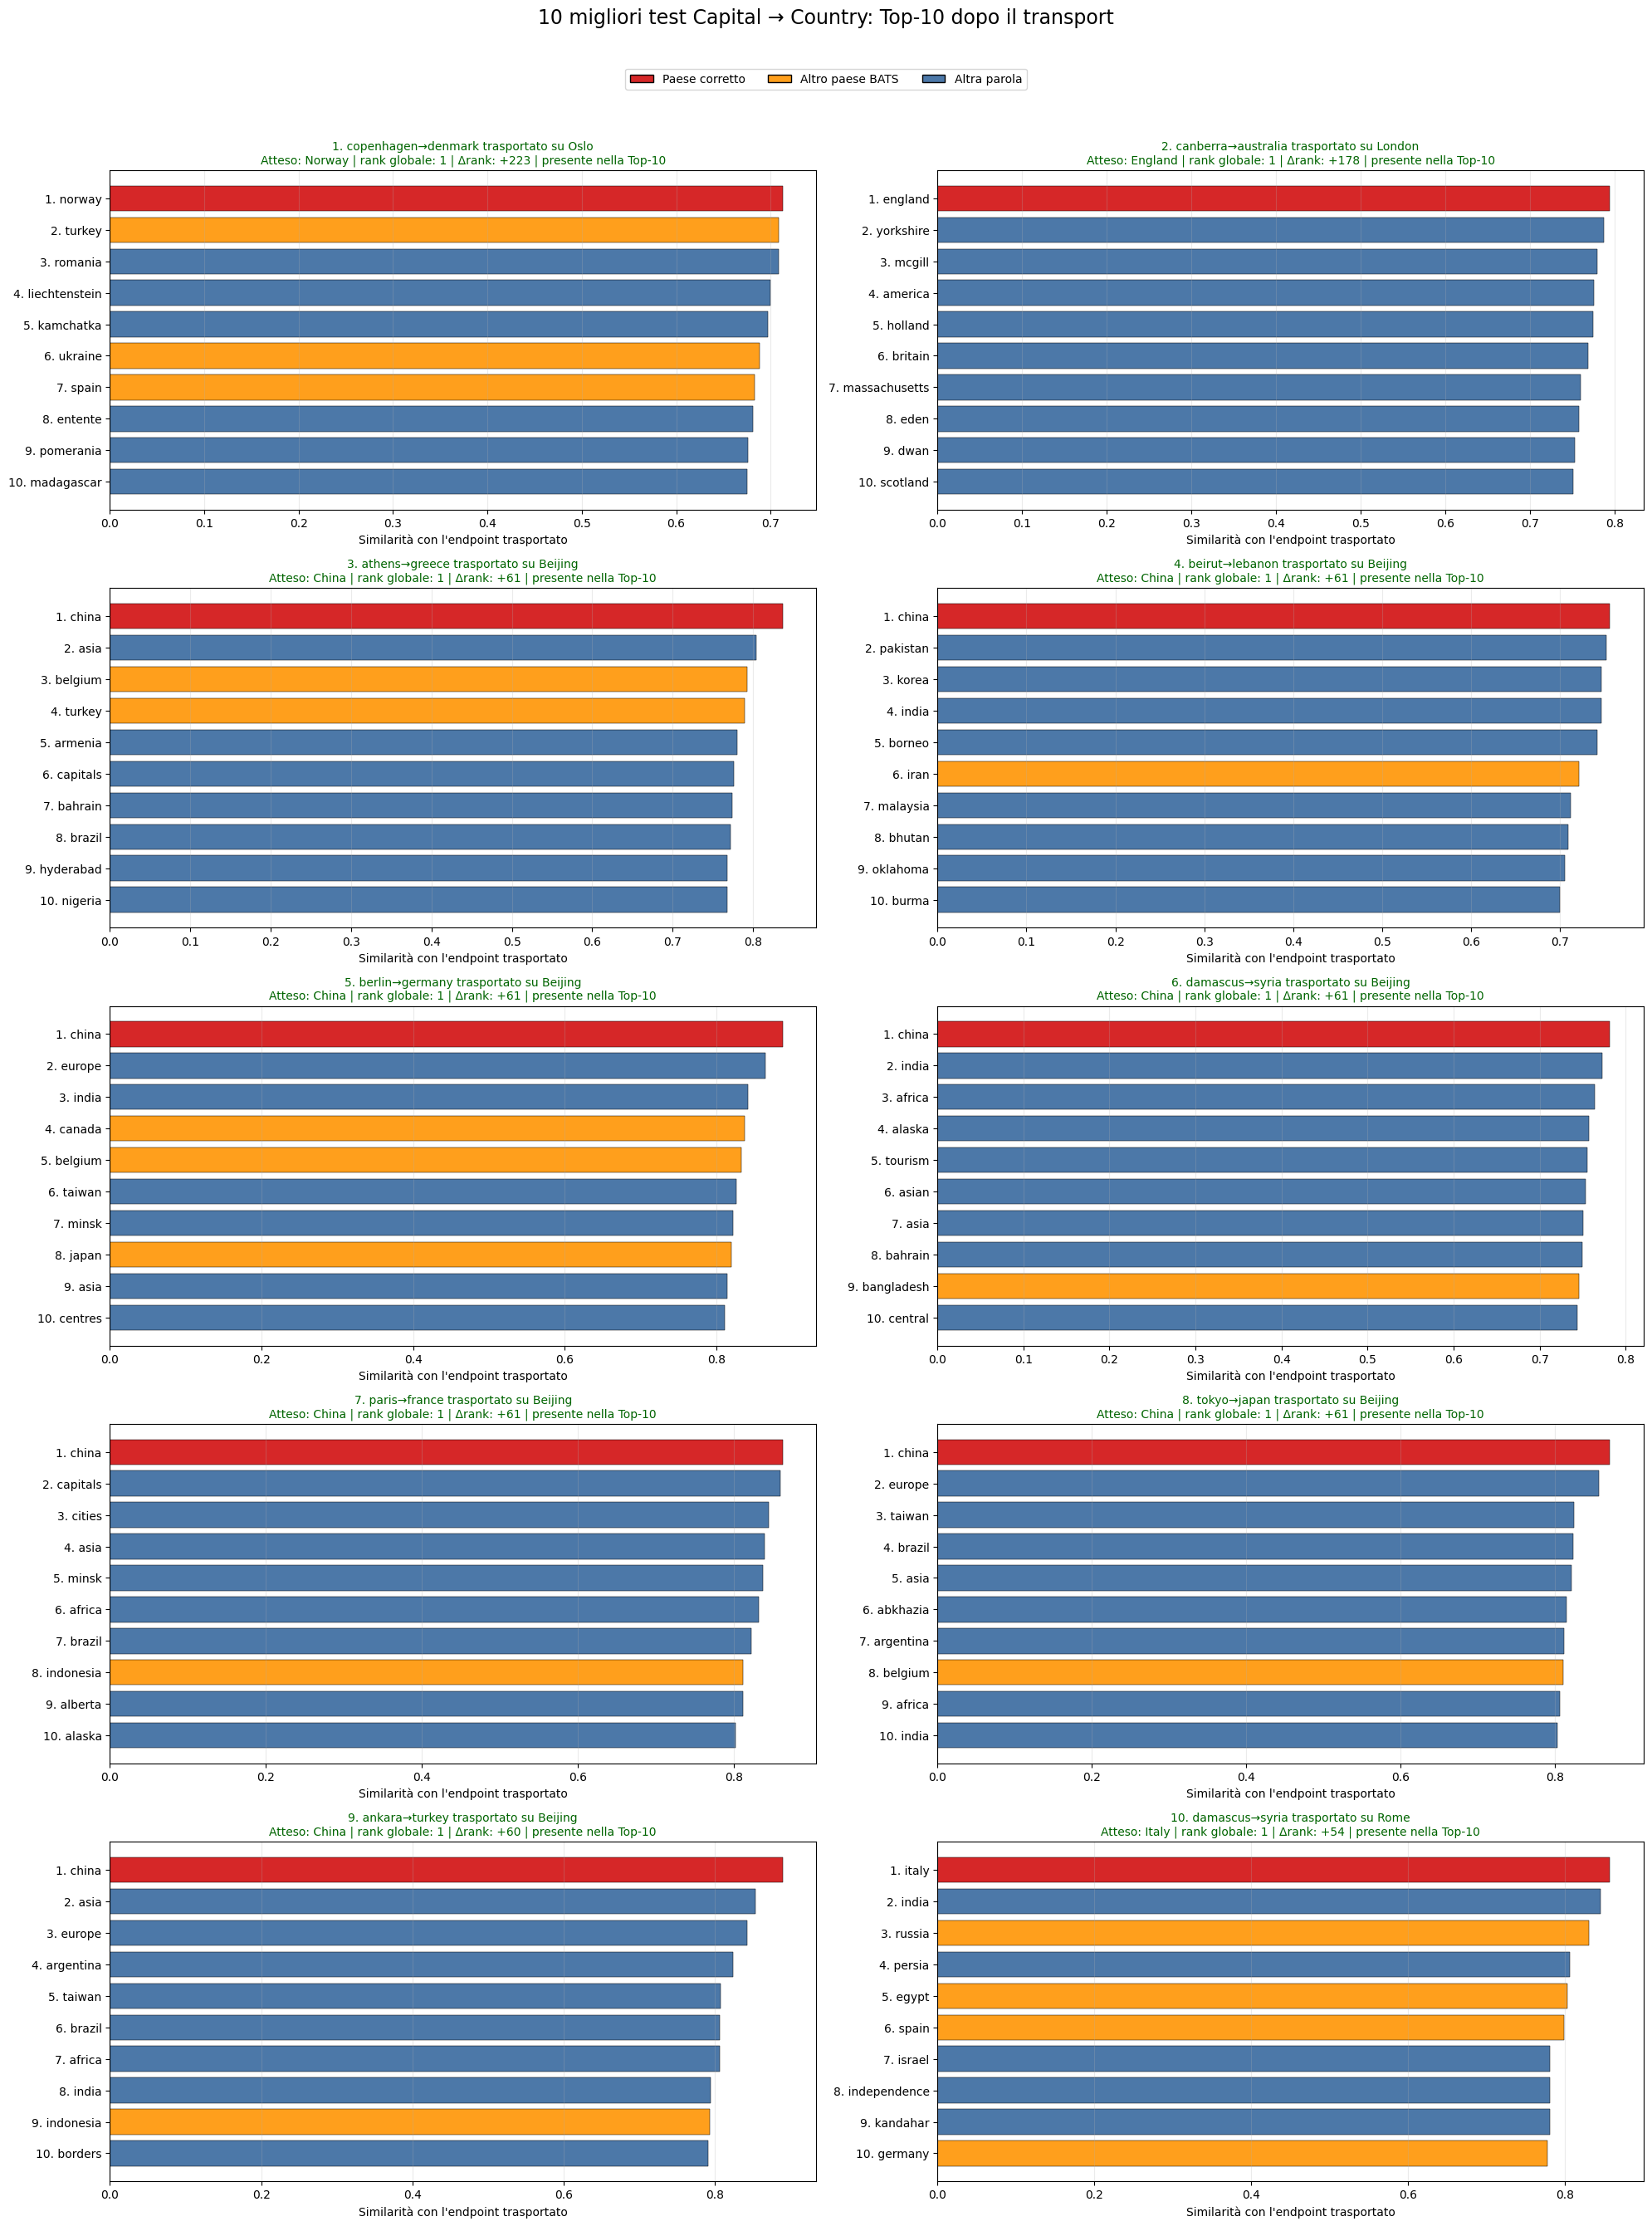

LISTA DETTAGLIATA DEI VICINI PER I 10 TEST MIGLIORI


,gruppo,test_n,source_relation,target_test,rank_target_globale,posizione_top_k,parola,cosine_similarity,tipo
0,migliori,1,copenhagen→denmark,oslo→norway,1,1,norway,0.712676,paese corretto
1,migliori,1,copenhagen→denmark,oslo→norway,1,2,turkey,0.708904,altro paese BATS
2,migliori,1,copenhagen→denmark,oslo→norway,1,3,romania,0.708341,altra parola
3,migliori,1,copenhagen→denmark,oslo→norway,1,4,liechtenstein,0.699554,altra parola
4,migliori,1,copenhagen→denmark,oslo→norway,1,5,kamchatka,0.696783,altra parola
5,migliori,1,copenhagen→denmark,oslo→norway,1,6,ukraine,0.688568,altro paese BATS
6,migliori,1,copenhagen→denmark,oslo→norway,1,7,spain,0.683517,altro paese BATS
7,migliori,1,copenhagen→denmark,oslo→norway,1,8,entente,0.681605,altra parola
8,migliori,1,copenhagen→denmark,oslo→norway,1,9,pomerania,0.676294,altra parola
9,migliori,1,copenhagen→denmark,oslo→norway,1,10,madagascar,0.674809,altra parola


In [32]:
# ============================================================
# 18. Visualizzazione dei 10 test migliori
# ============================================================

plot_selected_transport_top10(
    BEST_10_TESTS_DF,
    (
        "10 migliori test Capital → Country: "
        "Top-10 dopo il transport"
    ),
)

BEST_10_NEIGHBORS_DF = (
    build_selected_top10_table(
        BEST_10_TESTS_DF,
        group_name="migliori",
    )
)

print(
    "LISTA DETTAGLIATA DEI VICINI "
    "PER I 10 TEST MIGLIORI"
)

display(
    BEST_10_NEIGHBORS_DF.style.apply(
        highlight_selected_neighbor,
        axis=1,
    )
)

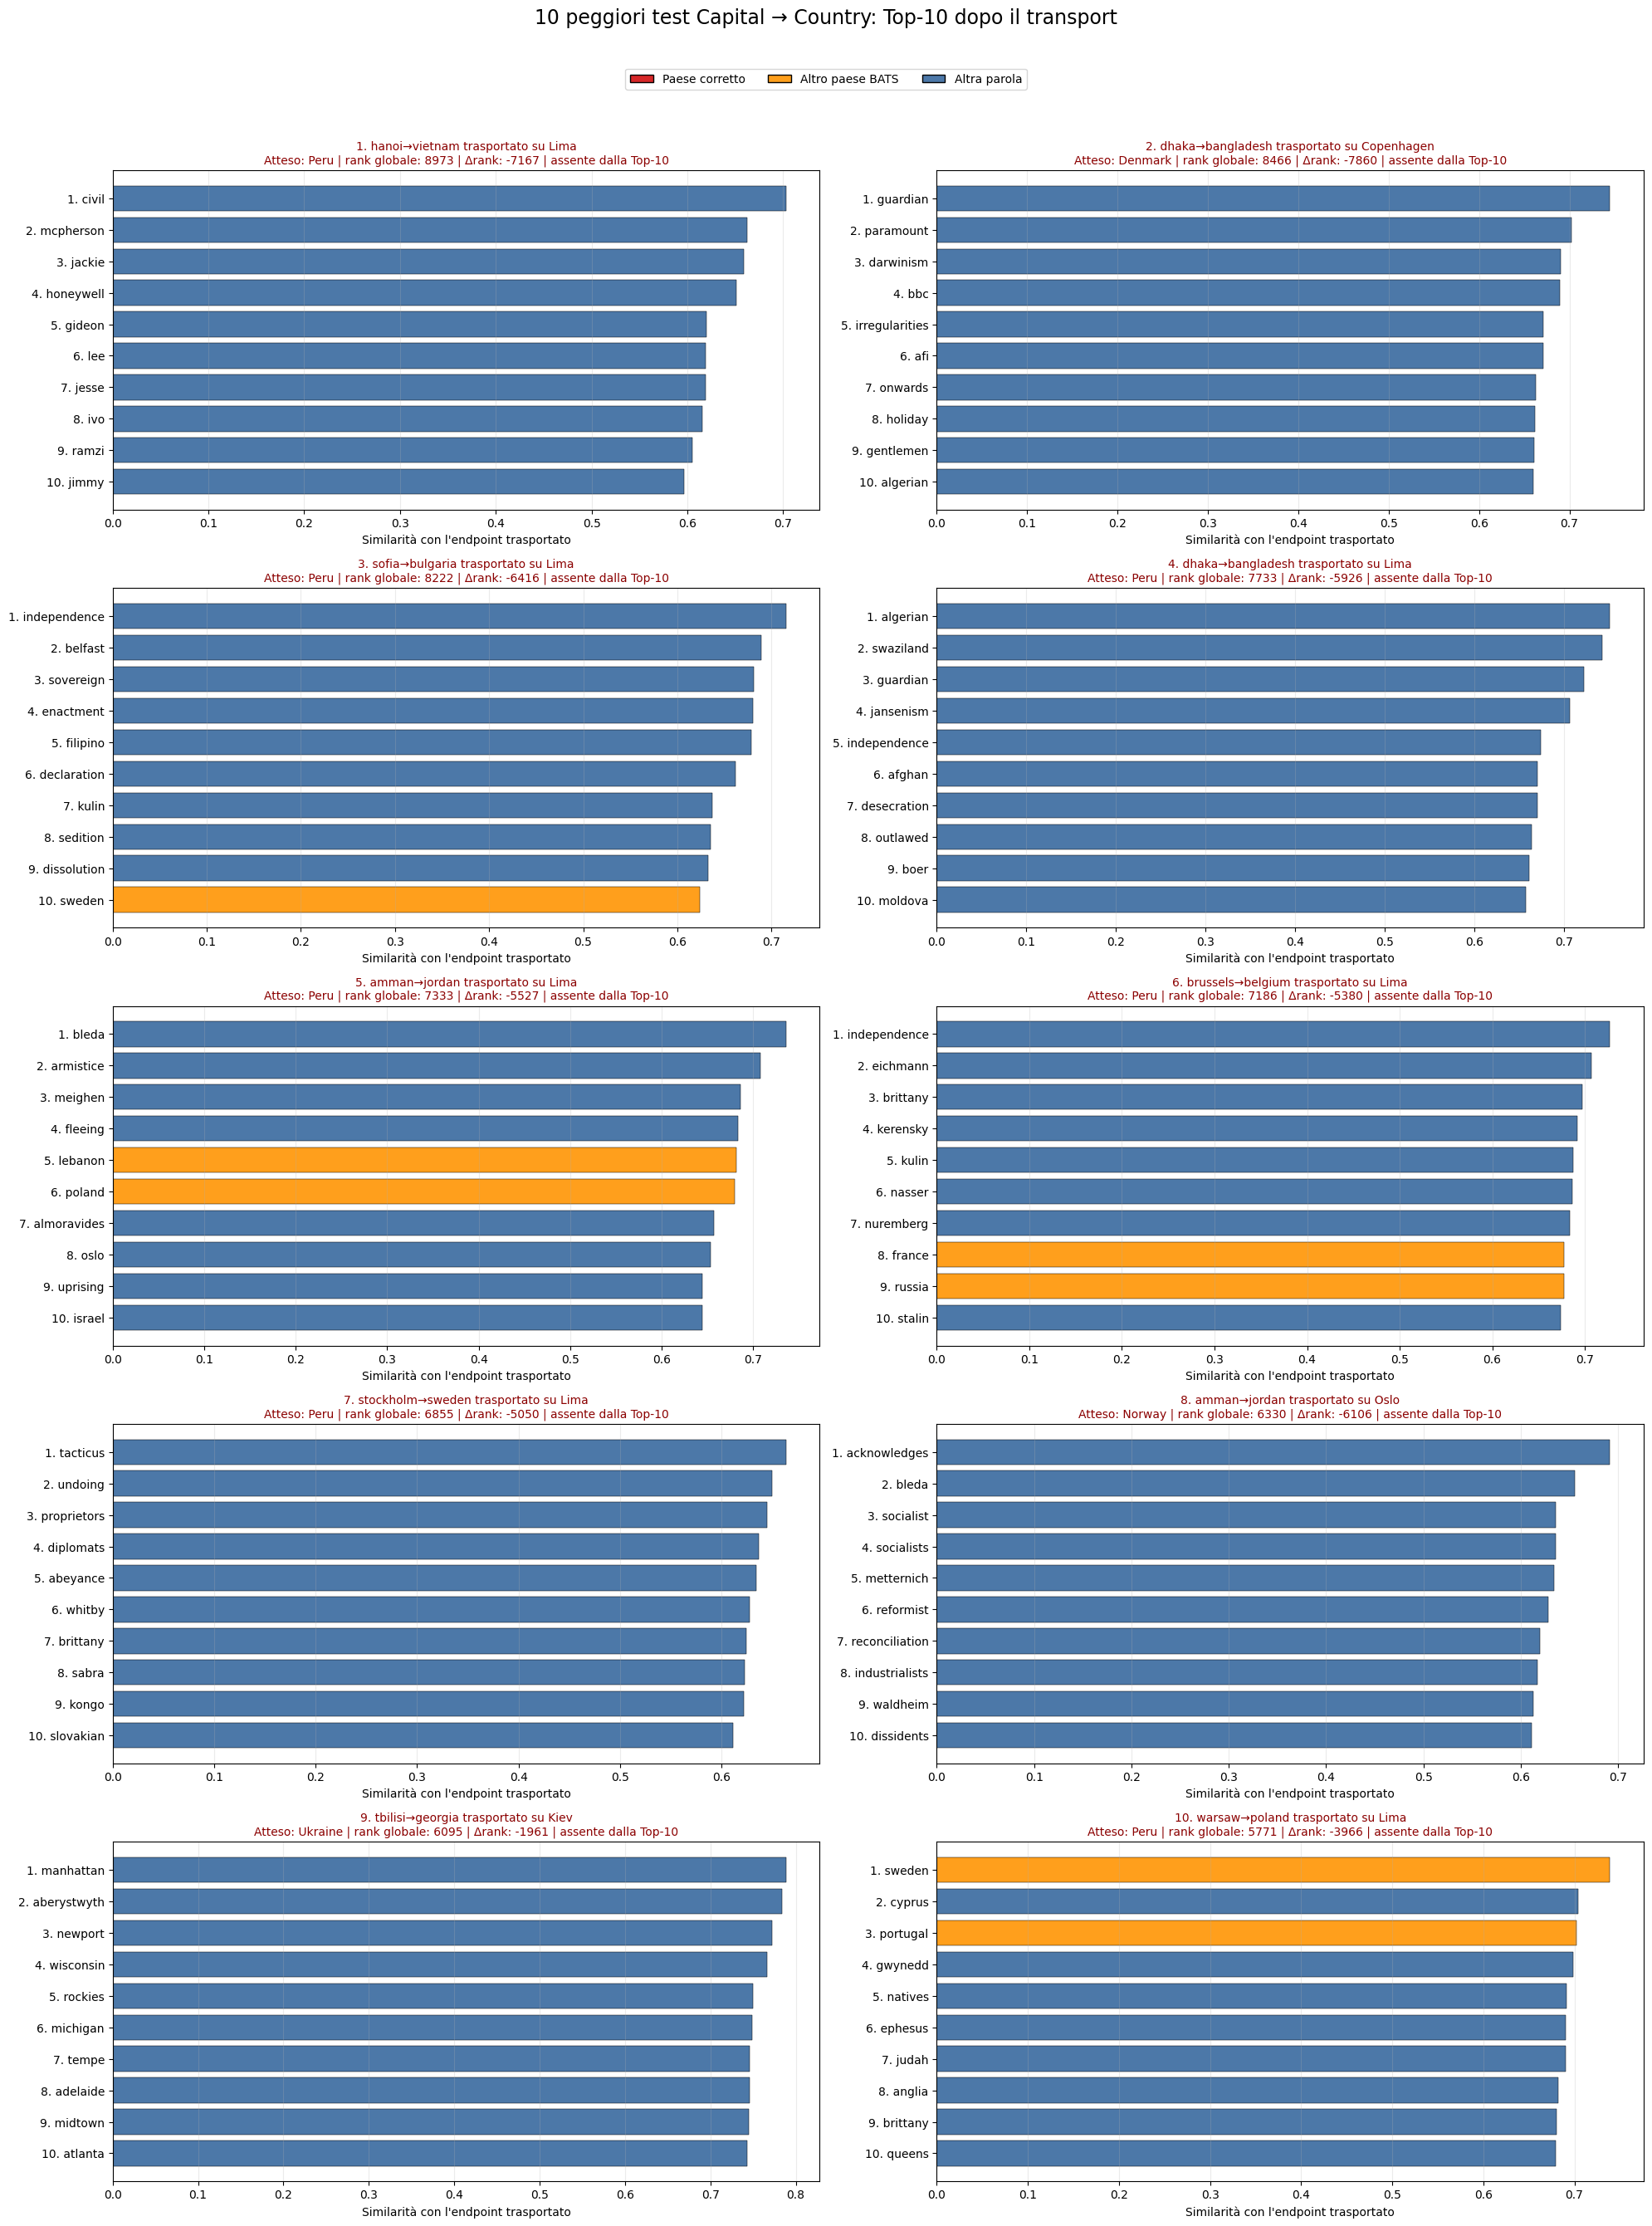

LISTA DETTAGLIATA DEI VICINI PER I 10 TEST PEGGIORI


,gruppo,test_n,source_relation,target_test,rank_target_globale,posizione_top_k,parola,cosine_similarity,tipo
0,peggiori,1,hanoi→vietnam,lima→peru,8973,1,civil,0.702909,altra parola
1,peggiori,1,hanoi→vietnam,lima→peru,8973,2,mcpherson,0.662575,altra parola
2,peggiori,1,hanoi→vietnam,lima→peru,8973,3,jackie,0.659070,altra parola
3,peggiori,1,hanoi→vietnam,lima→peru,8973,4,honeywell,0.650948,altra parola
4,peggiori,1,hanoi→vietnam,lima→peru,8973,5,gideon,0.620142,altra parola
5,peggiori,1,hanoi→vietnam,lima→peru,8973,6,lee,0.618788,altra parola
6,peggiori,1,hanoi→vietnam,lima→peru,8973,7,jesse,0.618710,altra parola
7,peggiori,1,hanoi→vietnam,lima→peru,8973,8,ivo,0.615627,altra parola
8,peggiori,1,hanoi→vietnam,lima→peru,8973,9,ramzi,0.605198,altra parola
9,peggiori,1,hanoi→vietnam,lima→peru,8973,10,jimmy,0.596297,altra parola


In [33]:
# ============================================================
# 19. Visualizzazione dei 10 test peggiori
# ============================================================

plot_selected_transport_top10(
    WORST_10_TESTS_DF,
    (
        "10 peggiori test Capital → Country: "
        "Top-10 dopo il transport"
    ),
)

WORST_10_NEIGHBORS_DF = (
    build_selected_top10_table(
        WORST_10_TESTS_DF,
        group_name="peggiori",
    )
)

print(
    "LISTA DETTAGLIATA DEI VICINI "
    "PER I 10 TEST PEGGIORI"
)

display(
    WORST_10_NEIGHBORS_DF.style.apply(
        highlight_selected_neighbor,
        axis=1,
    )
)